# Assignment 1: What drives the price of a car?
**Author:** Mbuya  |  **Dataset:** `automobileEDA.csv` (201 cars, 29 columns)

**Objective:** use exploratory data analysis and statistical techniques to find the variables that most influence a car's price, and turn the findings into a pricing recommendation for a dealer.

| Section | Question |
|---|---|
| 1 | Explore the features, handle missing values, duplicates and outliers, save `Mbuya Data.csv` |
| 2 | Descriptive statistics and distributions |
| 3 | Average price by group (drive-wheels, body-style, ...) |
| 4 | Effect of continuous, categorical and paired categorical variables on price |
| 5 | Feature selection and a recommendation for the dealer |

Every output below is followed by a short explanation of what it shows.

In [7]:
import warnings
warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
BLUE, ORANGE = "#2f6f8f", "#d9822b"
RANDOM_STATE = 42

## 1. Data exploration and cleaning

### 1.1 First look at the data

In [8]:
raw = pd.read_csv("automobileEDA.csv")
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (201, 29)


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


**What this shows.** The file has 201 cars and 29 columns: 1 target (`price`) and 28 candidate columns that describe the engine, size, body, drivetrain and fuel economy. `length` and `width` are already rescaled to roughly 0 to 1, while `height` and `wheel-base` are in inches.

In [9]:
pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(), "first value": raw.iloc[0]})

,dtype,n_unique,first value
symboling,int64,6,3
normalized-losses,int64,51,122
make,str,22,alfa-romero
aspiration,str,2,std
num-of-doors,str,2,two
body-style,str,5,convertible
drive-wheels,str,3,rwd
engine-location,str,2,front
wheel-base,float64,52,88.6
length,float64,73,0.811148


**What this shows.** 10 columns are text (categorical) and 19 are numeric. Some numeric columns are really categories: `symboling` is an insurance risk rating (-2 to 3) and `diesel`/`gas` are 0/1 flags. `horsepower-binned` is a Low/Medium/High grouping of `horsepower`.

### 1.2 Candidate features for predicting price

In [10]:
target = "price"
groups = {
    "Continuous (measurements)": ["wheel-base", "length", "width", "height", "curb-weight", "engine-size",
                                  "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
                                  "city-mpg", "highway-mpg", "city-L/100km", "normalized-losses"],
    "Categorical (nominal)":     ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels",
                                  "engine-location", "engine-type", "fuel-system"],
    "Categorical (ordinal)":     ["num-of-cylinders", "symboling", "horsepower-binned"],
    "Binary fuel indicators":    ["diesel", "gas"],
}
for k, v in groups.items():
    print(f"{k} ({len(v)}): {', '.join(v)}")
print("\nTarget:", target)

Continuous (measurements) (15): wheel-base, length, width, height, curb-weight, engine-size, bore, stroke, compression-ratio, horsepower, peak-rpm, city-mpg, highway-mpg, city-L/100km, normalized-losses
Categorical (nominal) (8): make, aspiration, num-of-doors, body-style, drive-wheels, engine-location, engine-type, fuel-system
Categorical (ordinal) (3): num-of-cylinders, symboling, horsepower-binned
Binary fuel indicators (2): diesel, gas

Target: price


**What this shows.** The candidate predictors split into 15 continuous measurements, 11 categorical variables (nominal and ordinal) and 2 fuel flags. Continuous variables are tested with correlation and regression, categorical ones with group means and ANOVA.

### 1.3 Missing values

In [11]:
miss = raw.isna().sum()
miss = miss[miss > 0]
display_tbl = pd.DataFrame({"missing": miss, "% of rows": (miss / len(raw) * 100).round(2)})
print(display_tbl, "\n")
raw[raw.isna().any(axis=1)][["make", "body-style", "engine-type", "stroke", "horsepower", "horsepower-binned", "price"]]

                   missing  % of rows
stroke                   4       1.99
horsepower-binned        1       0.50 



,make,body-style,engine-type,stroke,horsepower,horsepower-binned,price
46,jaguar,sedan,ohcv,2.76,262.0,NaN,36000.0
52,mazda,hatchback,rotor,NaN,101.0,Low,10945.0
53,mazda,hatchback,rotor,NaN,101.0,Low,11845.0
54,mazda,hatchback,rotor,NaN,101.0,Low,13645.0
55,mazda,hatchback,rotor,NaN,135.0,Medium,15645.0


**What this shows.** Only two columns have gaps, 5 values in total (2% of `stroke` and 0.5% of `horsepower-binned`). All four missing `stroke` values are the Mazda rotary-engine cars. The one missing `horsepower-binned` value is the Jaguar with 262 hp, the most powerful car in the data. There are no other hidden placeholders such as `?`.

In [12]:
df = raw.copy()

# stroke: all 4 missing values belong to rotary (Wankel) engines, which have no piston stroke.
# The column is skewed by a few odd values, so the median is the safer fill.
print("Engine type of rows with missing stroke:", df.loc[df["stroke"].isna(), "engine-type"].unique())
df["stroke"] = df["stroke"].fillna(df["stroke"].median())

# horsepower-binned: see the horsepower range of each bin to place the one unlabelled car
print(df.groupby("horsepower-binned")["horsepower"].agg(["min", "max", "count"]), "\n")
print("Horsepower of the unlabelled car:", df.loc[df["horsepower-binned"].isna(), "horsepower"].iloc[0])
df["horsepower-binned"] = df["horsepower-binned"].fillna("High")

print("\nMissing values left:", int(df.isna().sum().sum()))

Engine type of rows with missing stroke: <StringArray>
['rotor']
Length: 1, dtype: str
                     min    max  count
horsepower-binned                     
High               156.0  207.0     23
Low                 48.0  101.0    115
Medium             102.0  155.0     62 

Horsepower of the unlabelled car: 262.0

Missing values left: 0


**What this shows.** Rotary engines have no piston stroke, so the value is genuinely not applicable. The column median (3.29) is used so these cars do not distort the average. The bins show Low is up to 101 hp, Medium is 102 to 155 hp and High is 156 to 207 hp, so the 262 hp Jaguar belongs in **High**. After this step no values are missing.

### 1.4 Duplicates

In [13]:
print("Exact duplicate rows:", raw.duplicated().sum())
same_but_price = raw.drop(columns="price").duplicated(keep=False)
print("Rows identical in every column except price:", same_but_price.sum())
raw.loc[same_but_price, ["make", "body-style", "engine-size", "curb-weight", "horsepower", "price"]].sort_values(["make", "price"])

Exact duplicate rows: 0
Rows identical in every column except price: 14


,make,body-style,engine-size,curb-weight,horsepower,price
0,alfa-romero,convertible,130,2548,111.0,13495.0
1,alfa-romero,convertible,130,2548,111.0,16500.0
24,dodge,sedan,90,1989,68.0,6692.0
25,dodge,sedan,90,1989,68.0,7609.0
57,mazda,sedan,122,2410,84.0,8495.0
56,mazda,hatchback,122,2385,84.0,8845.0
59,mazda,sedan,122,2410,84.0,10245.0
58,mazda,hatchback,122,2385,84.0,10595.0
52,mazda,hatchback,70,2380,101.0,10945.0
53,mazda,hatchback,70,2380,101.0,11845.0


**What this shows.** There are **no exact duplicate rows**. Fourteen rows match another car in every column except price (for example two Porsche hardtops at 32,528 and 34,028). These are different trim levels or listings of the same model with different prices, so they carry real information and are **kept**.

### 1.5 Inconsistent labels and impossible values

In [14]:
print(sorted(df["make"].unique()))
df["make"] = df["make"].replace({"peugot": "peugeot", "alfa-romero": "alfa-romeo"})
print("\nAfter fixing spelling:", sorted(df["make"].unique())[:3], "...")
print("\nShare of rows where normalized-losses equals 122:", round((raw["normalized-losses"] == 122).mean() * 100, 1), "%")

['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercedes-benz', 'mercury', 'mitsubishi', 'nissan', 'peugot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']

After fixing spelling: ['alfa-romeo', 'audi', 'bmw'] ...

Share of rows where normalized-losses equals 122: 20.4 %


**What this shows.** Two makes are misspelled: `peugot` (should be Peugeot) and `alfa-romero` (should be Alfa Romeo). Left alone they would split brands, so they are renamed (14 rows). Also, 20% of the `normalized-losses` values are exactly 122, which looks like a mean fill from the source data, so this column is a weak predictor and is treated with caution later.

In [15]:
# Engine displacement can be recomputed from bore, stroke and cylinder count:
#   displacement = pi/4 * bore^2 * stroke * cylinders      (cubic inches)
# For a correct row this should be very close to engine-size (ratio ~ 1). Rotary engines are excluded.
cyl = df["num-of-cylinders"].map({"two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "eight": 8, "twelve": 12})
ratio = np.pi / 4 * df["bore"] ** 2 * df["stroke"] * cyl / df["engine-size"]
print(ratio[df["engine-type"] != "rotor"].describe().round(3), "\n")

suspect = (df["engine-type"] != "rotor") & ((ratio < 0.9) | (ratio > 1.1))
df.loc[suspect, ["make", "body-style", "num-of-cylinders", "engine-size", "bore", "stroke"]].assign(ratio=ratio[suspect].round(2))

count    197.000
mean       0.992
std        0.066
min        0.347
25%        0.995
50%        0.999
75%        1.003
max        1.111
dtype: float64 



,make,body-style,num-of-cylinders,engine-size,bore,stroke,ratio
0,alfa-romeo,convertible,four,130,3.47,2.68,0.78
1,alfa-romeo,convertible,four,130,3.47,2.68,0.78
2,alfa-romeo,hatchback,six,152,2.68,3.47,0.77
108,peugeot,sedan,four,120,3.46,2.19,0.69
110,peugeot,wagon,four,120,3.46,2.19,0.69
126,renault,wagon,four,132,3.46,3.90,1.11
127,renault,hatchback,four,132,3.46,3.90,1.11
130,saab,hatchback,four,121,2.54,2.07,0.35


**What this shows.** For a correct row, the engine displacement computed from bore, stroke and cylinders should equal `engine-size`. For 189 of the 197 piston-engine cars the ratio is within 10% of 1 (median 0.999), so the check is reliable. Eight rows fail it. Reading them against their sister rows: the Saab (ratio 0.35) and two Peugeots (0.69) have typos in bore or stroke, and the Alfa Romeo hatchback (0.77) has bore and stroke swapped. The two Alfa convertibles (0.78) and the two Renaults (1.11) are off by less and cannot be resolved from the data, so they are left unchanged.

In [16]:
# Fix the rows where the evidence points to a clear data-entry error
saab = (df["make"] == "saab") & (df["bore"] == 2.54)                         # 2.54 / 2.07 are typos of 3.54 / 3.07 (sister saab rows)
df.loc[saab, ["bore", "stroke"]] = [3.54, 3.07]
peug = (df["make"] == "peugeot") & (df["stroke"] == 2.19)                    # 2.19 is a typo of 3.19 (identical engines in other rows)
df.loc[peug, "stroke"] = 3.19
alfa = (df["make"] == "alfa-romeo") & (df["engine-type"] == "ohcv")          # bore and stroke are swapped
df.loc[alfa, ["bore", "stroke"]] = df.loc[alfa, ["stroke", "bore"]].values

ratio = np.pi / 4 * df["bore"] ** 2 * df["stroke"] * cyl / df["engine-size"]
fixed = saab | peug | alfa
print(f"Rows corrected: {fixed.sum()}")
df.loc[fixed, ["make", "engine-size", "bore", "stroke"]].assign(new_ratio=ratio[fixed].round(2))

Rows corrected: 4


,make,engine-size,bore,stroke,new_ratio
2,alfa-romeo,152,3.47,2.68,1.0
108,peugeot,120,3.46,3.19,1.0
110,peugeot,120,3.46,3.19,1.0
130,saab,121,3.54,3.07,1.0


**What this shows.** Four rows were corrected and each now recomputes to a ratio of 1.0, which confirms the fixes: Saab bore 2.54 to 3.54 and stroke 2.07 to 3.07, Peugeot stroke 2.19 to 3.19 (two rows), and Alfa Romeo bore and stroke swapped back.

### 1.6 Outliers

In [17]:
num_cols = ["normalized-losses", "wheel-base", "length", "width", "height", "curb-weight", "engine-size", "bore",
            "stroke", "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "city-L/100km", "price"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append((c, round(lo, 2), round(hi, 2), n_out, round(n_out / len(df) * 100, 1)))
out_tbl = pd.DataFrame(rows, columns=["variable", "lower fence", "upper fence", "n outliers", "% of rows"]).set_index("variable")
out_tbl

,lower fence,upper fence,n outliers,% of rows
variable,,,,
normalized-losses,47.00,191.00,8,4.0
wheel-base,82.65,114.25,3,1.5
length,0.68,1.00,1,0.5
width,0.84,0.98,11,5.5
height,46.75,60.75,0,0.0
curb-weight,1033.50,4061.50,2,1.0
engine-size,33.50,205.50,10,5.0
bore,2.50,4.23,0,0.0
stroke,2.69,3.85,24,11.9


**What this shows.** The IQR rule (values beyond 1.5 times the interquartile range) flags values in most columns. The biggest counts are `compression-ratio` (27 cars) and `stroke` (24), and `price` has 14 outliers (7% of cars). Most columns have 0 to 5.5% flagged.

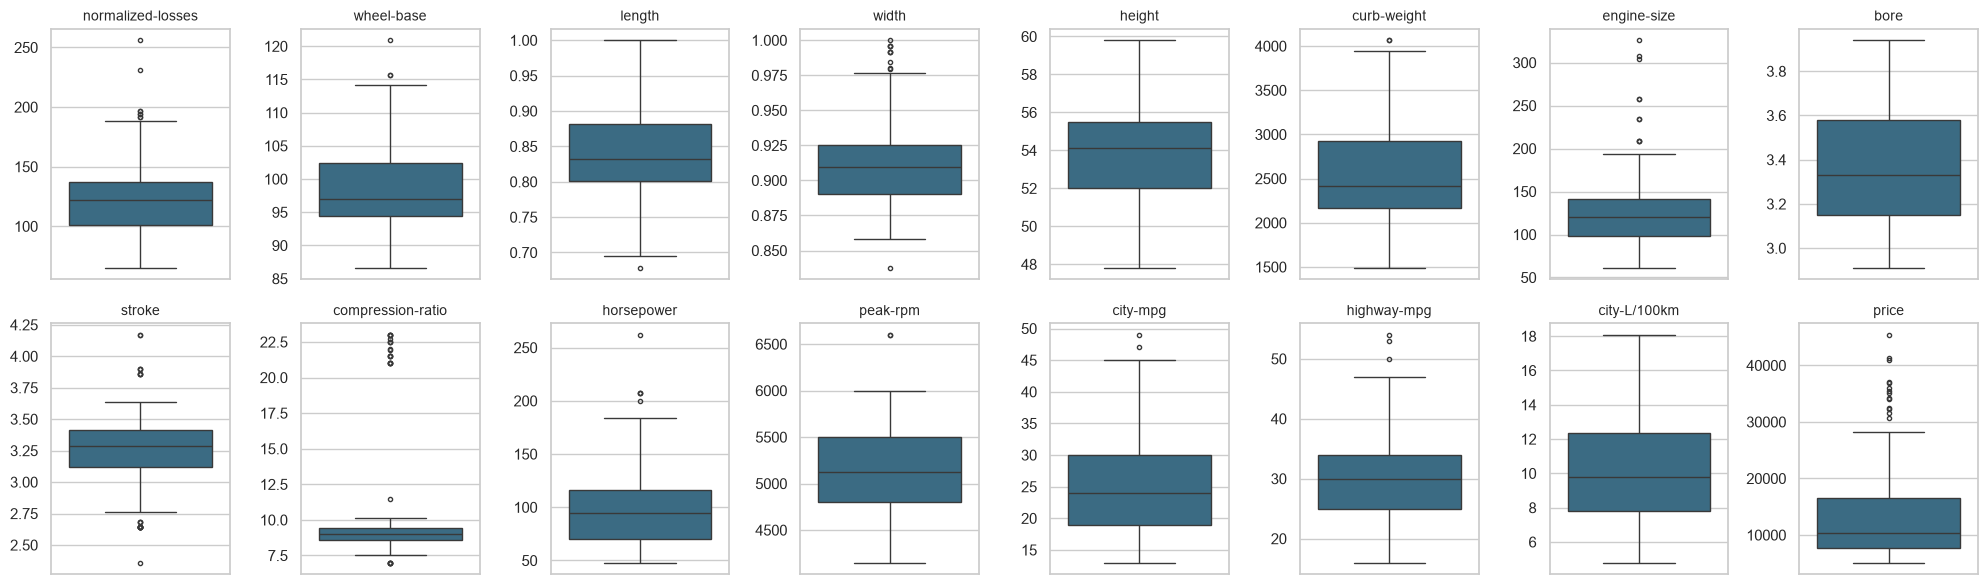

In [18]:
fig, axes = plt.subplots(2, 8, figsize=(20, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color=BLUE, fliersize=3)
    ax.set_title(c, fontsize=10); ax.set_ylabel("")
plt.tight_layout()

**What this shows.** The box plots confirm that the outliers sit on the high side for price, engine size, horsepower and width, i.e. large and powerful cars. `compression-ratio` is clearly two-humped (about 9 for petrol versus about 22 for diesel), which is why so many cars are flagged.

In [19]:
q1, q3 = df["price"].quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
print(f"Price upper fence: {upper:,.0f}\n")
print(df.loc[df["price"] > upper, ["make", "body-style", "engine-size", "horsepower", "price"]].sort_values("price", ascending=False).to_string(), "\n")

# Compression-ratio outliers: are they diesels?
hi_cr = df["compression-ratio"] > 15
print("Cars with compression ratio > 15:", hi_cr.sum(), "| of which diesel:", int(df.loc[hi_cr, "diesel"].sum()))

Price upper fence: 29,588

              make   body-style  engine-size  horsepower    price
71   mercedes-benz      hardtop          304       184.0  45400.0
15             bmw        sedan          209       182.0  41315.0
70   mercedes-benz        sedan          308       184.0  40960.0
125        porsche  convertible          194       207.0  37028.0
16             bmw        sedan          209       182.0  36880.0
46          jaguar        sedan          326       262.0  36000.0
45          jaguar        sedan          258       176.0  35550.0
69   mercedes-benz  convertible          234       155.0  35056.0
68   mercedes-benz        sedan          234       155.0  34184.0
124        porsche      hardtop          194       207.0  34028.0
123        porsche      hardtop          194       207.0  32528.0
44          jaguar        sedan          258       176.0  32250.0
67   mercedes-benz        sedan          183       123.0  31600.0
14             bmw        sedan          209     

**What this shows.** All 14 price outliers are premium makes: Mercedes-Benz, BMW, Jaguar and Porsche, priced between 30,760 and 45,400, with large engines (183 to 326). They are genuine vehicles, not errors. All 20 cars with compression ratio above 15 are diesels, which is normal for diesel engines.

**Decision on outliers.** Outliers were only changed when the evidence showed a data-entry error (Section 1.5). Statistical outliers that are real vehicles (high-priced luxury cars, diesel compression ratios, high-rpm engines) are kept, because removing them would delete exactly the expensive cars whose price we are trying to explain. Where a method is sensitive to extreme values later on (correlation), a rank-based check (Spearman) is shown next to it.

### 1.7 Save the cleaned dataset

In [20]:
assert df.isna().sum().sum() == 0 and df.duplicated().sum() == 0
df.to_csv("Mbuya Data.csv", index=False)
print("Saved 'Mbuya Data.csv':", df.shape)
summary = pd.DataFrame({"step": ["Missing stroke", "Missing horsepower-binned", "Misspelt makes", "Bore/stroke errors", "Duplicates", "Price and other outliers"],
                        "rows affected": [4, 1, int(raw["make"].isin(["peugot", "alfa-romero"]).sum()), int(fixed.sum()), 0, 0],
                        "action": ["Filled with median", "Set to 'High' from horsepower", "Renamed", "Corrected", "None found", "Kept (genuine vehicles)"]}).set_index("step")
summary

Saved 'Mbuya Data.csv': (201, 29)


,rows affected,action
step,,
Missing stroke,4,Filled with median
Missing horsepower-binned,1,Set to 'High' from horsepower
Misspelt makes,14,Renamed
Bore/stroke errors,4,Corrected
Duplicates,0,None found
Price and other outliers,0,Kept (genuine vehicles)


**What this shows.** The cleaned dataset (201 rows, 29 columns, no missing values, no duplicates) is saved as `Mbuya Data.csv`. The table lists what was changed: 5 values filled, 14 make names corrected, 4 engine measurements corrected. Everything else is original.

## 2. Descriptive statistics and distributions

In [21]:
data = pd.read_csv("Mbuya Data.csv")
data["fuel-type"] = np.where(data["diesel"] == 1, "diesel", "gas")        # one readable column in place of the two dummies

continuous = ["normalized-losses", "wheel-base", "length", "width", "height", "curb-weight", "engine-size", "bore", "stroke",
              "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "city-L/100km"]
categorical = ["make", "aspiration", "fuel-type", "num-of-doors", "body-style", "drive-wheels", "engine-location",
               "engine-type", "num-of-cylinders", "fuel-system", "symboling", "horsepower-binned"]
print("Cleaned data loaded:", data.shape)

Cleaned data loaded: (201, 30)


**What this shows.** The cleaned file is reloaded (so the analysis uses exactly what is submitted) and a readable `fuel-type` column (gas or diesel) is added for analysis only. This gives 14 continuous predictors plus `normalized-losses`, and 12 categorical variables.

### 2.1 Summary statistics of the continuous variables

In [22]:
desc = data[continuous + ["price"]].describe().T
desc["median"] = data[continuous + ["price"]].median()
desc["skew"] = data[continuous + ["price"]].skew()
desc["kurtosis"] = data[continuous + ["price"]].kurt()
desc = desc[["count", "mean", "median", "std", "min", "25%", "75%", "max", "skew", "kurtosis"]].round(2)
desc

,count,mean,median,std,min,25%,75%,max,skew,kurtosis
normalized-losses,201.0,122.00,122.00,32.00,65.00,101.00,137.00,256.00,0.85,1.32
wheel-base,201.0,98.80,97.00,6.07,86.60,94.50,102.40,120.90,1.03,0.95
length,201.0,0.84,0.83,0.06,0.68,0.80,0.88,1.00,0.15,-0.07
width,201.0,0.92,0.91,0.03,0.84,0.89,0.92,1.00,0.88,0.68
height,201.0,53.77,54.10,2.45,47.80,52.00,55.50,59.80,0.03,-0.43
curb-weight,201.0,2555.67,2414.00,517.30,1488.00,2169.00,2926.00,4066.00,0.71,0.03
engine-size,201.0,126.88,120.00,41.55,61.00,98.00,141.00,326.00,1.98,5.50
bore,201.0,3.34,3.33,0.26,2.91,3.15,3.58,3.94,0.09,-1.12
stroke,201.0,3.27,3.29,0.29,2.36,3.12,3.41,4.17,-0.23,1.14
compression-ratio,201.0,10.16,9.00,4.00,7.00,8.60,9.40,23.00,2.58,5.07


**What this shows.** Prices range from 5,118 to 45,400, with a mean (13,207) well above the median (10,295), so price is **right-skewed** (skew 1.81). `engine-size` (skew 1.98), `compression-ratio` (2.58) and `horsepower` (1.15) are also right-skewed because a few large, powerful cars pull the tail out. `height`, `length`, `bore`, `stroke` and `peak-rpm` are close to symmetric (skew between -0.23 and 0.15). The typical car has a 97-inch wheel base, weighs about 2,400 lb, has a 120 cu-in engine and 95 hp.

### 2.2 Frequency counts of the categorical variables

In [23]:
for c in categorical:
    t = data[c].value_counts()
    print(pd.DataFrame({"count": t, "%": (t / len(data) * 100).round(1)}).rename_axis(c).to_string(), "\n")

               count     %
make                      
toyota            32  15.9
nissan            18   9.0
mazda             17   8.5
honda             13   6.5
mitsubishi        13   6.5
subaru            12   6.0
volkswagen        12   6.0
peugeot           11   5.5
volvo             11   5.5
dodge              9   4.5
bmw                8   4.0
mercedes-benz      8   4.0
plymouth           7   3.5
audi               6   3.0
saab               6   3.0
porsche            4   2.0
alfa-romeo         3   1.5
chevrolet          3   1.5
jaguar             3   1.5
isuzu              2   1.0
renault            2   1.0
mercury            1   0.5 

            count     %
aspiration             
std           165  82.1
turbo          36  17.9 

           count     %
fuel-type             
gas          181  90.0
diesel        20  10.0 

              count     %
num-of-doors             
four            115  57.2
two              86  42.8 

             count     %
body-style              
se

**What this shows.** The market in this data is dominated by ordinary cars: 82% have standard (non-turbo) aspiration, 90% run on gas, 59% are front-wheel drive, 78% have four cylinders, and 98.5% have the engine at the front. Sedans (47%) and hatchbacks (34%) make up most of the body styles. Toyota is the largest make (16%), and several makes have very few cars (Mercury 1, Isuzu 2, Renault 2), so their averages are unreliable. Rare categories such as `rear` engine (3 cars), `twelve` cylinders (1) and `three` cylinders (1) should be read with care.

### 2.3 Distribution of price

mean 13,207 | median 10,295 | skew 1.81 | skew of log price 0.68


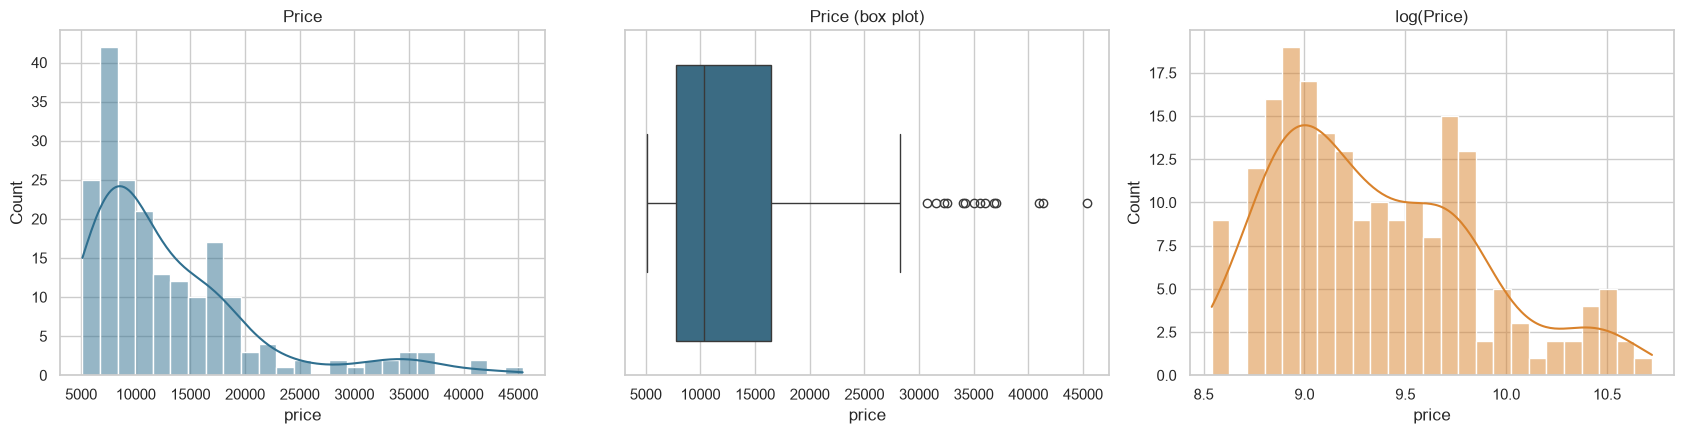

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(data["price"], bins=25, kde=True, color=BLUE, ax=axes[0]); axes[0].set_title("Price")
sns.boxplot(x=data["price"], color=BLUE, ax=axes[1]); axes[1].set_title("Price (box plot)")
sns.histplot(np.log(data["price"]), bins=25, kde=True, color=ORANGE, ax=axes[2]); axes[2].set_title("log(Price)")
plt.tight_layout()
print(f"mean {data.price.mean():,.0f} | median {data.price.median():,.0f} | skew {data.price.skew():.2f} | skew of log price {np.log(data.price).skew():.2f}")

**What this shows.** Price is clearly right-skewed: most cars cost between 7,800 and 16,500 (the middle half), while a small group of premium cars reaches 45,400. The box plot marks those as outliers. Taking the log of price removes most of the skew (from 1.81 to 0.68), which suggests price grows in proportion to car size and power rather than by fixed amounts.

### 2.4 Distribution of the continuous variables

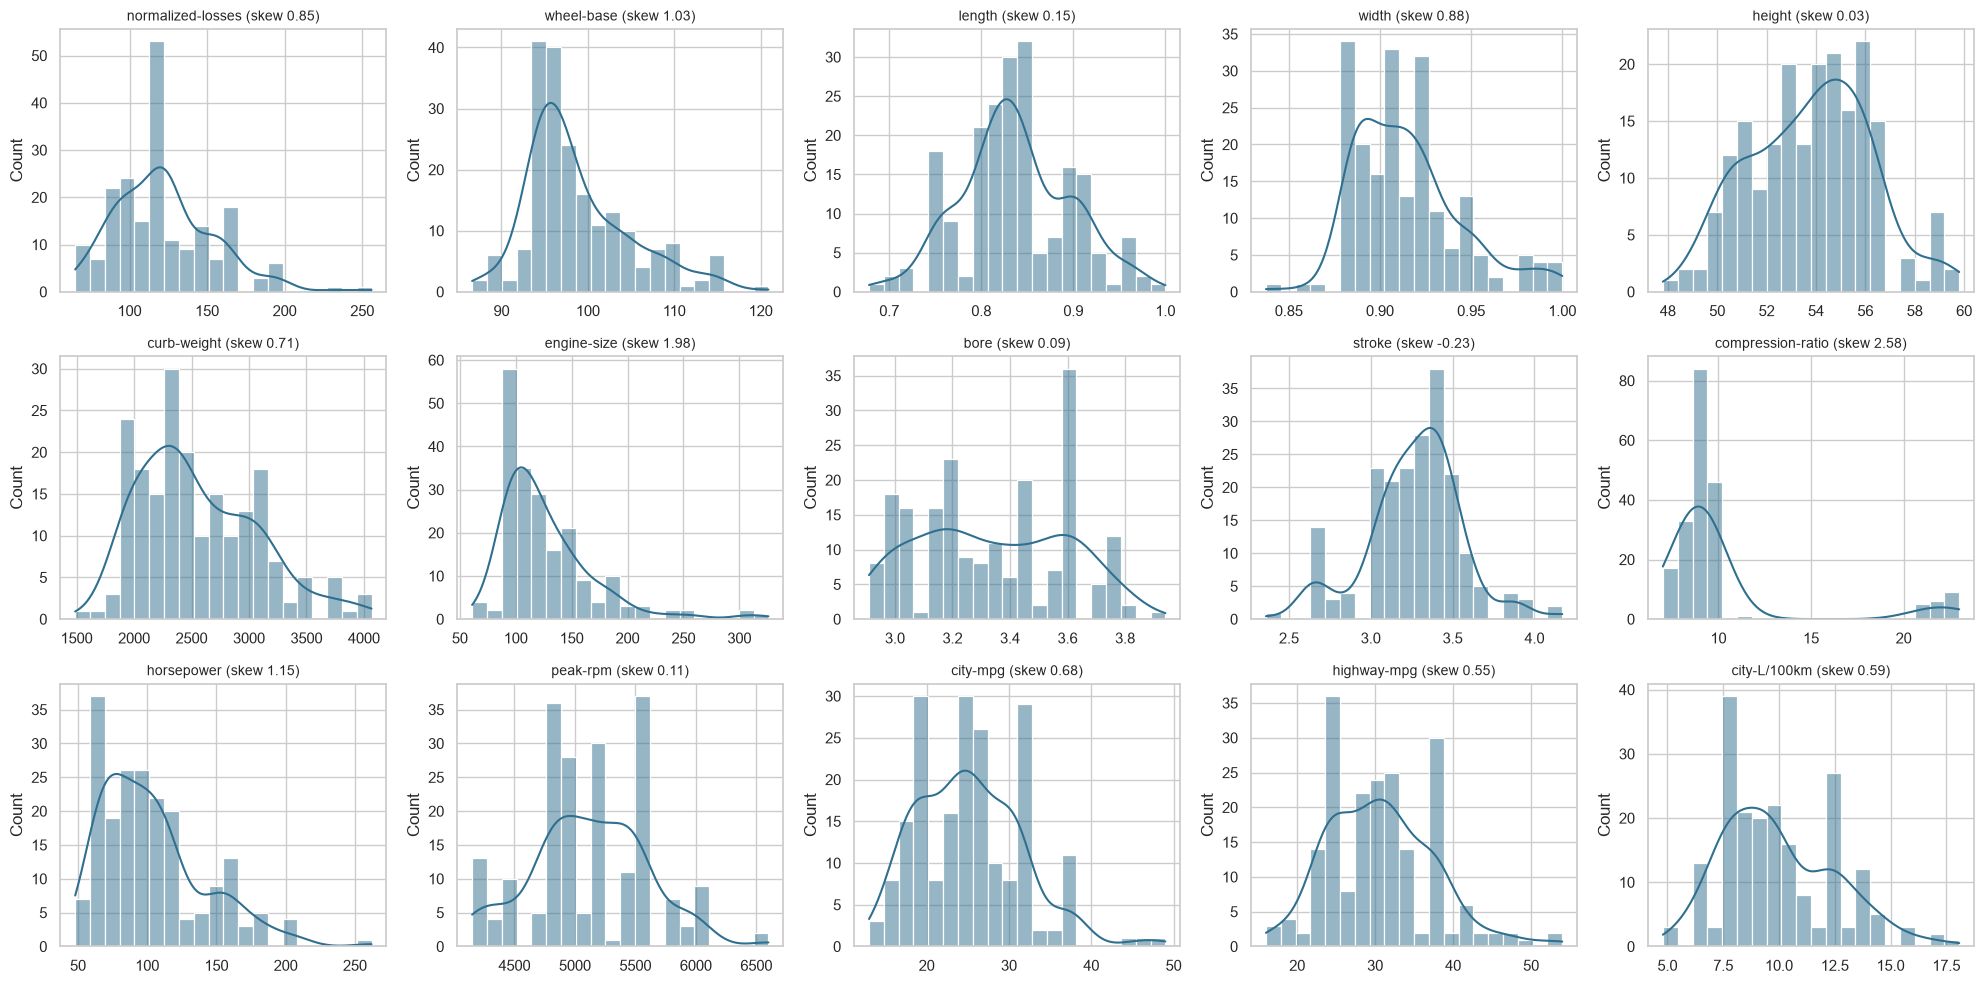

In [25]:
fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, c in zip(axes.ravel(), continuous):
    sns.histplot(data[c], bins=20, kde=True, color=BLUE, ax=ax)
    ax.set_title(f"{c} (skew {data[c].skew():.2f})", fontsize=10); ax.set_xlabel("")
plt.tight_layout()

**What this shows.** Several variables are right-skewed (engine size, horsepower, compression ratio, wheel base), while `height`, `bore`, `stroke` and `peak-rpm` are closer to bell-shaped. `compression-ratio` has two separate clusters (petrol around 9, diesel around 22). `city-mpg` and `highway-mpg` are also mildly right-skewed: most cars fall in the 20 to 35 mpg range, with a few very economical small cars.

### 2.5 Distribution of the categorical variables

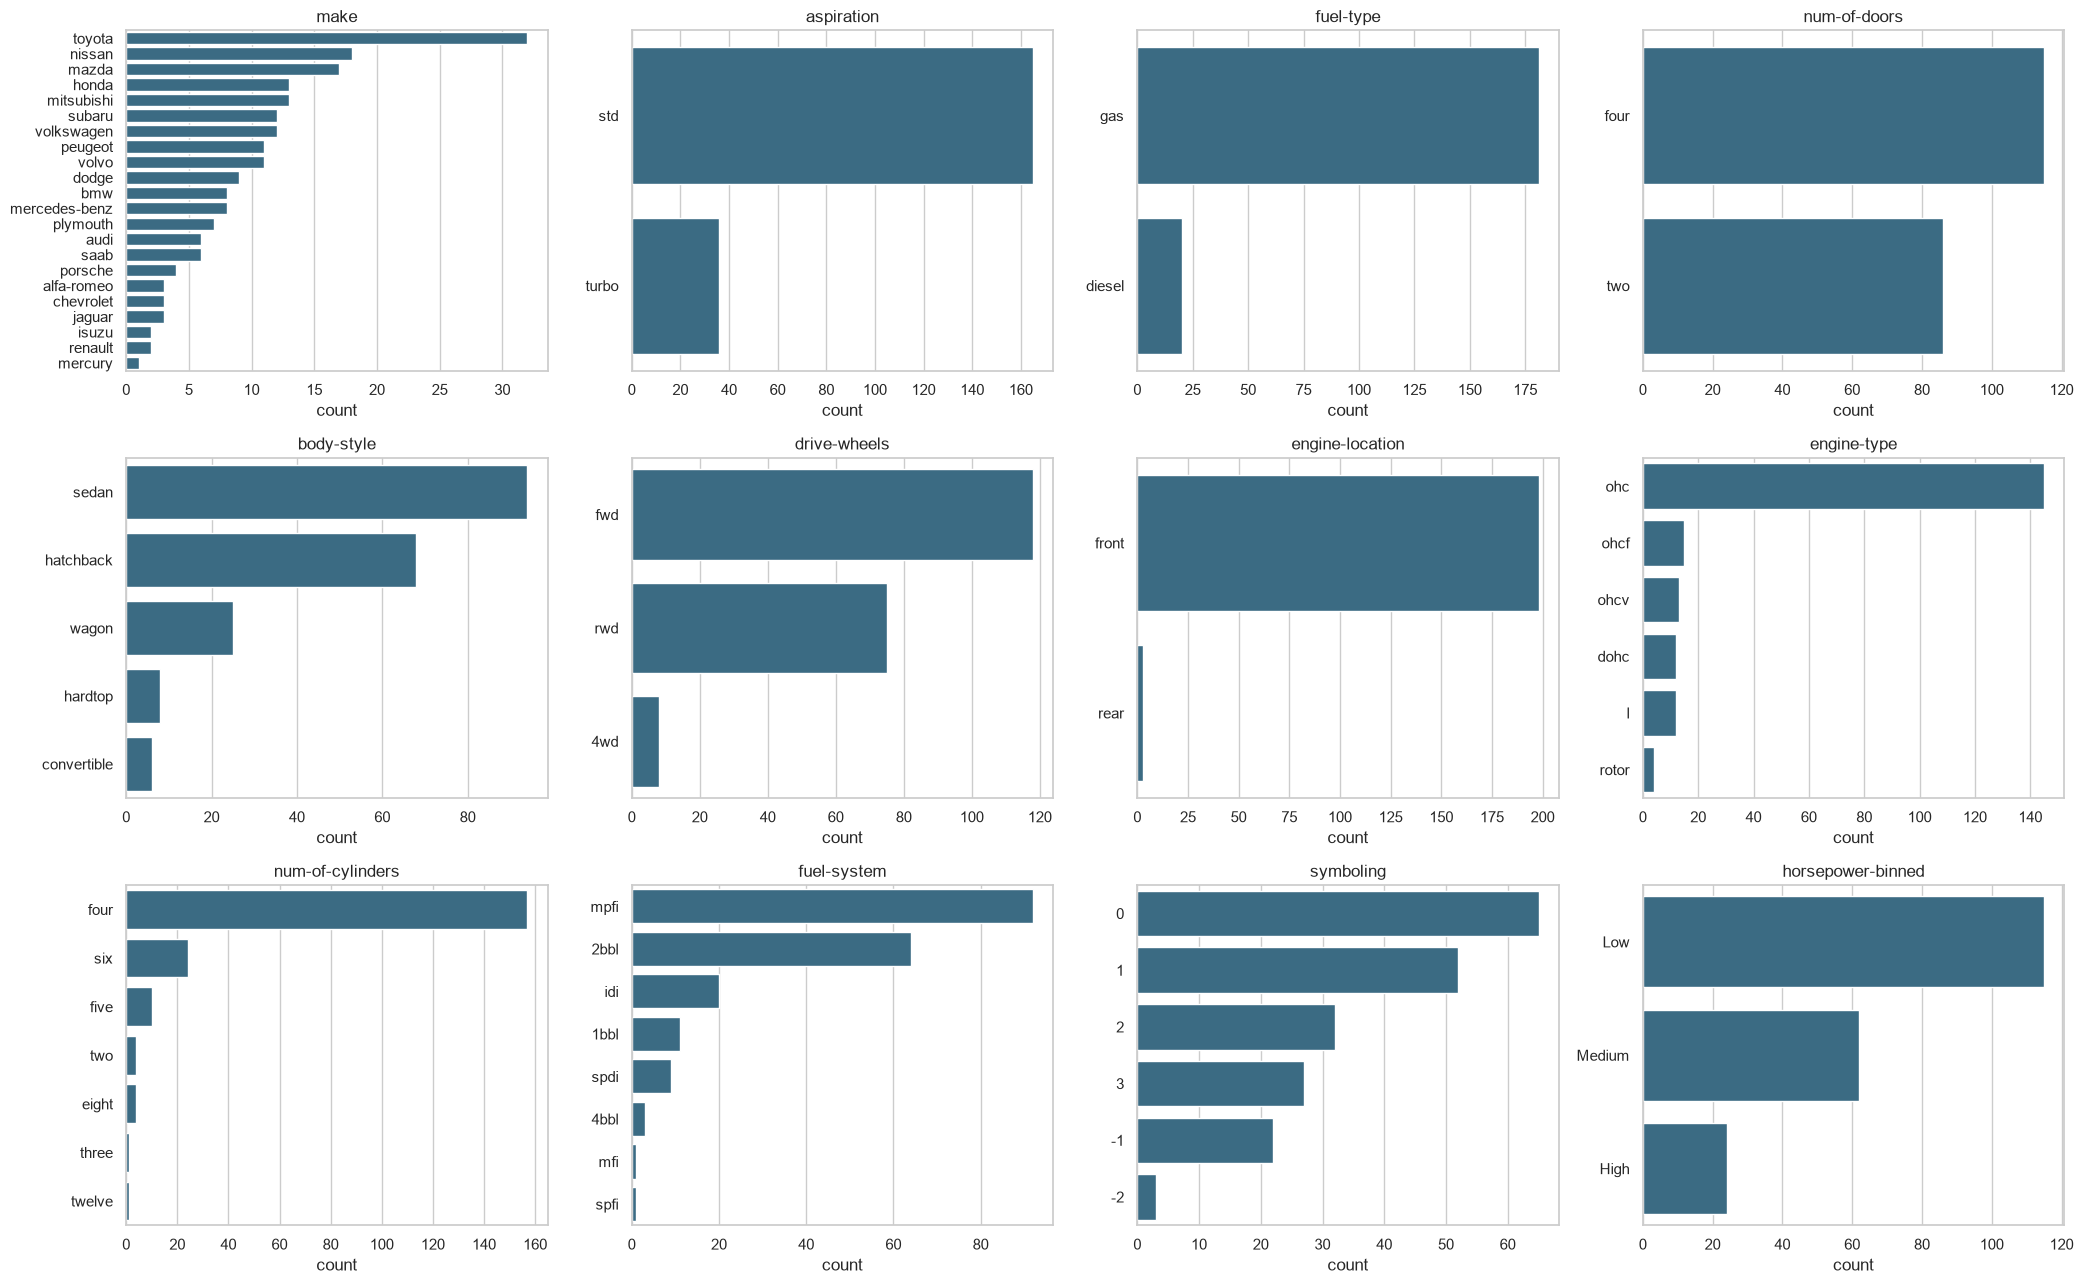

In [26]:
fig, axes = plt.subplots(3, 4, figsize=(21, 13))
for ax, c in zip(axes.ravel(), categorical):
    order = data[c].value_counts().index
    sns.countplot(data=data, y=c, order=order, color=BLUE, ax=ax)
    ax.set_title(c); ax.set_ylabel("")
plt.tight_layout()

**What this shows.** The bar charts give the same message as the frequency tables: most categories are dominated by one or two levels (std, gas, fwd, ohc, four cylinders, mpfi or 2bbl fuel system), and the data thins out quickly for luxury or unusual configurations. Because those rare groups also tend to be the expensive ones, they have an outsized effect on price patterns.

## 3. Average price by group

In [27]:
def group_summary(col):
    g = data.groupby(col)["price"].agg(count="count", mean="mean", median="median", std="std", min="min", max="max")
    return g.sort_values("mean", ascending=False).round(0)

by_drive = group_summary("drive-wheels")
by_body = group_summary("body-style")
print("Average price by drive-wheels"); print(by_drive.to_string(), "\n")
print("Average price by body-style");   print(by_body.to_string())

Average price by drive-wheels
              count     mean   median     std     min      max
drive-wheels                                                  
rwd              75  19758.0  16900.0  9083.0  6785.0  45400.0
4wd               8  10241.0   9006.0  3288.0  7603.0  17450.0
fwd             118   9245.0   8192.0  3346.0  5118.0  23875.0 

Average price by body-style
             count     mean   median      std      min      max
body-style                                                     
hardtop          8  22208.0  19688.0  14556.0   8249.0  45400.0
convertible      6  21890.0  17084.0  11188.0  11595.0  37028.0
sedan           94  14460.0  11078.0   8523.0   5499.0  41315.0
wagon           25  12372.0  11694.0   5121.0   6918.0  28248.0
hatchback       68   9957.0   8672.0   4149.0   5118.0  22018.0


**What this shows.** Rear-wheel drive cars are by far the most expensive (mean 19,758, median 16,900), almost twice the price of front-wheel drive cars (mean 9,245). Four-wheel drive (10,241) is priced close to front-wheel drive, but only 8 cars are in that group. By body style, hardtops (22,208) and convertibles (21,890) are the most expensive and hatchbacks the cheapest (9,957), with sedans (14,460) and wagons (12,372) in between. Hardtop and convertible averages rest on only 8 and 6 cars and have large spreads.

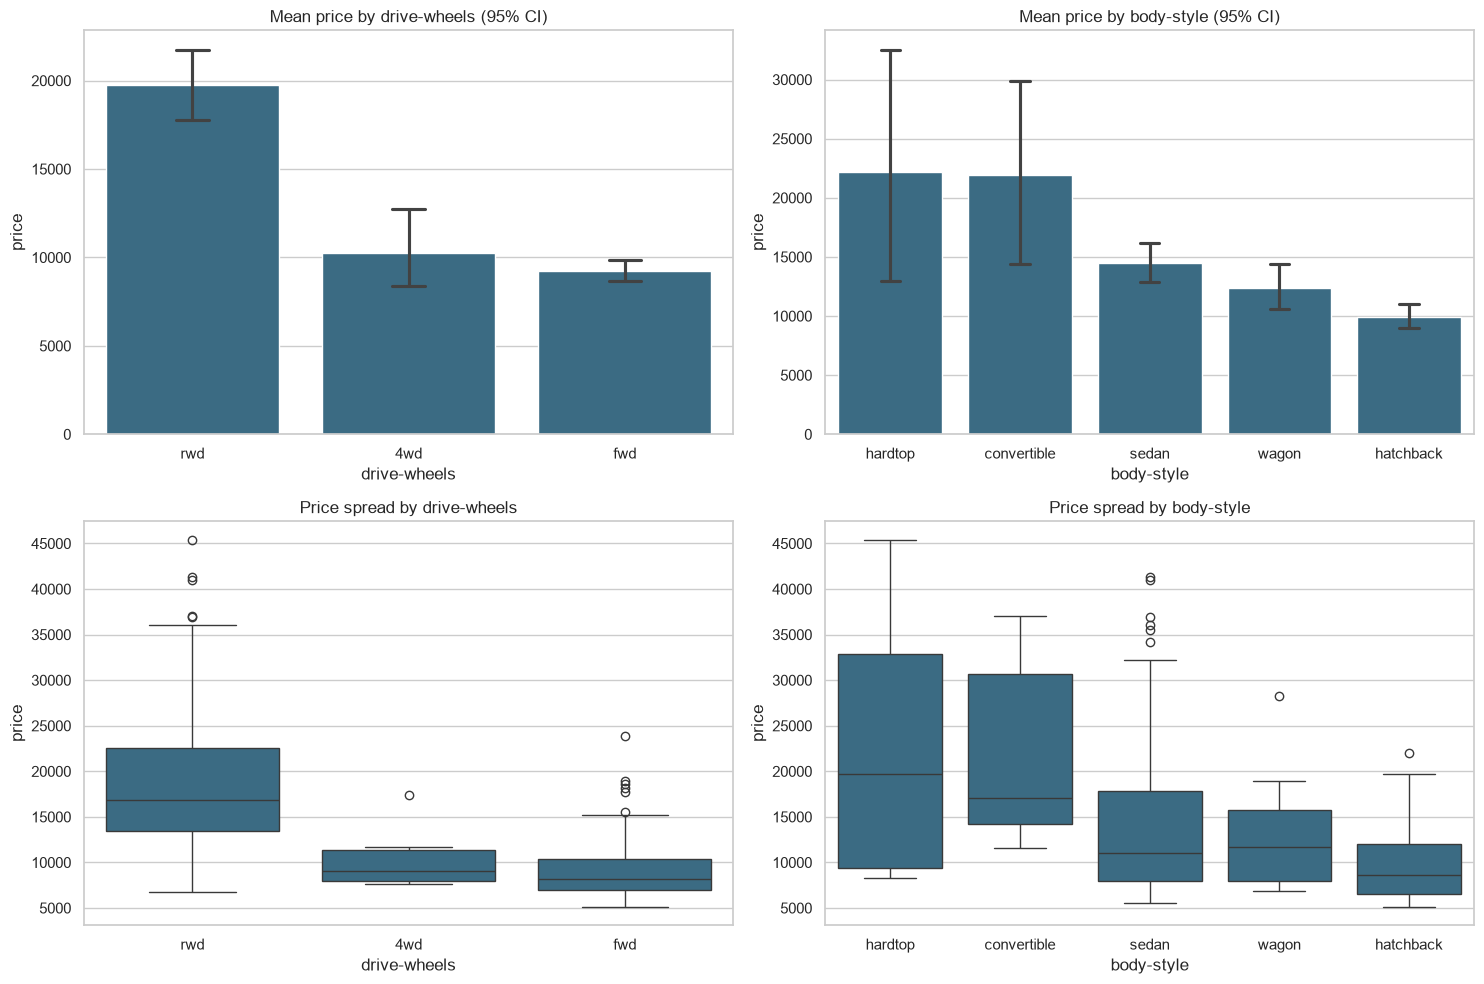

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for j, col in enumerate(["drive-wheels", "body-style"]):
    order = data.groupby(col)["price"].mean().sort_values(ascending=False).index
    sns.barplot(data=data, x=col, y="price", order=order, color=BLUE, errorbar=("ci", 95), capsize=.15, ax=axes[0, j])
    axes[0, j].set_title(f"Mean price by {col} (95% CI)")
    sns.boxplot(data=data, x=col, y="price", order=order, color=BLUE, ax=axes[1, j])
    axes[1, j].set_title(f"Price spread by {col}")
plt.tight_layout()

**What this shows.** The bars show the mean with a 95% confidence interval. The interval for rwd does not overlap with fwd or 4wd, so the drive-wheel difference is real and not noise. For body style, hatchbacks sit clearly below hardtops and convertibles, but the hardtop and convertible intervals are wide and overlap with the others, so their ranking is less certain. The box plots show that rwd, hardtop and convertible all have wide price spreads, meaning those groups mix cheap and luxury cars.

Mean price by drive-wheels x body-style
body-style    convertible  hardtop  hatchback    sedan    wagon
drive-wheels                                                   
4wd                   NaN      NaN     7603.0  12647.0   9096.0
fwd               11595.0   8249.0     8396.0   9812.0   9997.0
rwd               23950.0  24203.0    14338.0  21712.0  16994.0 

Number of cars in each cell
body-style    convertible  hardtop  hatchback  sedan  wagon
drive-wheels                                               
4wd                     0        0          1      3      4
fwd                     1        1         49     55     12
rwd                     5        7         18     36      9


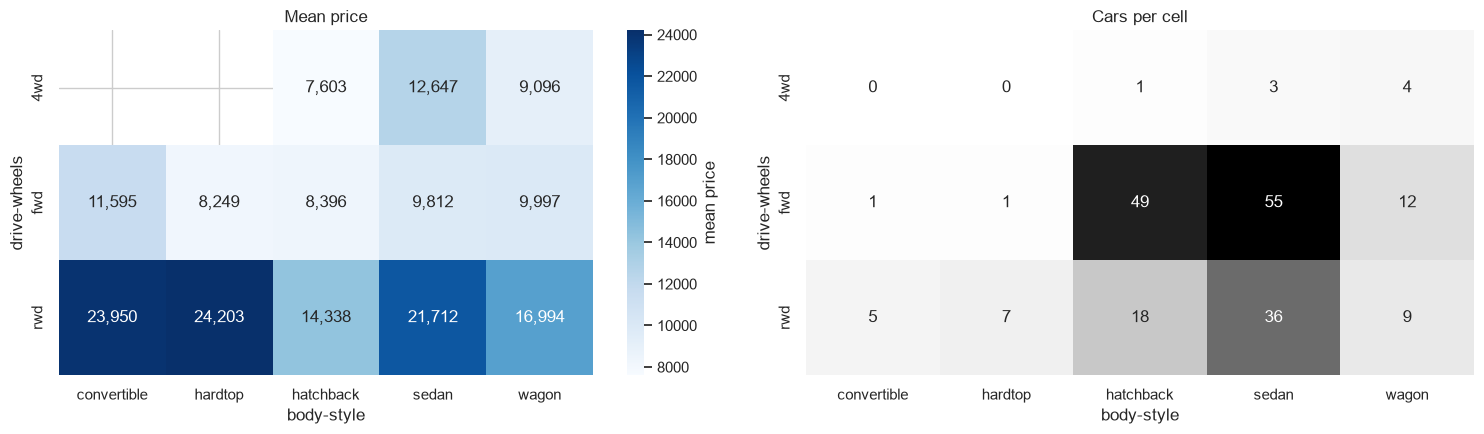

In [29]:
pivot_mean = data.pivot_table(values="price", index="drive-wheels", columns="body-style", aggfunc="mean").round(0)
pivot_n = data.pivot_table(values="price", index="drive-wheels", columns="body-style", aggfunc="count").fillna(0).astype(int)
print("Mean price by drive-wheels x body-style"); print(pivot_mean.to_string(), "\n")
print("Number of cars in each cell"); print(pivot_n.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(pivot_mean, annot=True, fmt=",.0f", cmap="Blues", ax=axes[0], cbar_kws={"label": "mean price"})
axes[0].set_title("Mean price")
sns.heatmap(pivot_n, annot=True, fmt="d", cmap="Greys", ax=axes[1], cbar=False)
axes[1].set_title("Cars per cell")
plt.tight_layout()

**What this shows.** Combining the two variables shows that drive-wheels matters within every body style: for sedans, rwd cars average 21,712 versus 9,812 for fwd; for hatchbacks 14,338 versus 8,396. The most expensive cell is **rwd hardtop (24,203)**, followed by **rwd convertible (23,950)**. The cheapest is **4wd hatchback (7,603)**, but that is a single car; among cells with many cars the fwd hatchback (8,396, 49 cars) is the cheapest. The right-hand panel shows the number of cars in each cell, and the cells with only 1 to 3 cars should not be over-interpreted.

In [30]:
for col in ["drive-wheels", "body-style"]:
    g = group_summary(col)
    print(f"{col:13s} highest: {g.index[0]} ({g['mean'].iloc[0]:,.0f})   lowest: {g.index[-1]} ({g['mean'].iloc[-1]:,.0f})")

cell = pivot_mean.stack(); cell = cell[pivot_n.stack() > 0]
print(f"\nDrive-wheels x body-style  highest: {cell.idxmax()} ({cell.max():,.0f})   lowest: {cell.idxmin()} ({cell.min():,.0f})")

# Beyond the two requested groupings: make, which turned out to matter
by_make = group_summary("make")
print("\nMakes, highest and lowest mean price (n >= 3):")
m = by_make[by_make["count"] >= 3]
print(pd.concat([m.head(4), m.tail(4)])[["count", "mean", "median"]].to_string())

drive-wheels  highest: rwd (19,758)   lowest: fwd (9,245)
body-style    highest: hardtop (22,208)   lowest: hatchback (9,957)

Drive-wheels x body-style  highest: ('rwd', 'hardtop') (24,203)   lowest: ('4wd', 'hatchback') (7,603)

Makes, highest and lowest mean price (n >= 3):
               count     mean   median
make                                  
jaguar             3  34600.0  35550.0
mercedes-benz      8  33647.0  32892.0
porsche            4  31400.0  33278.0
bmw                8  26119.0  22835.0
honda             13   8185.0   7295.0
plymouth           7   7963.0   7609.0
dodge              9   7875.0   7609.0
chevrolet          3   6007.0   6295.0


**What this shows.**
- **Highest average price:** rwd for drive-wheels (19,758), hardtop for body-style (22,208), and rwd hardtop for the combination (24,203).
- **Lowest average price:** fwd for drive-wheels (9,245), hatchback for body-style (9,957), and 4wd hatchback for the combination (7,603, a single car).

By make, Jaguar (34,600), Mercedes-Benz (33,647), Porsche (31,400) and BMW (26,119) are the highest, while Chevrolet (6,007), Dodge (7,875), Plymouth (7,963) and Honda (8,185) are the lowest. The make gap (about 28,000) is much bigger than the drive-wheel or body-style gaps, which hints that brand is a strong factor.

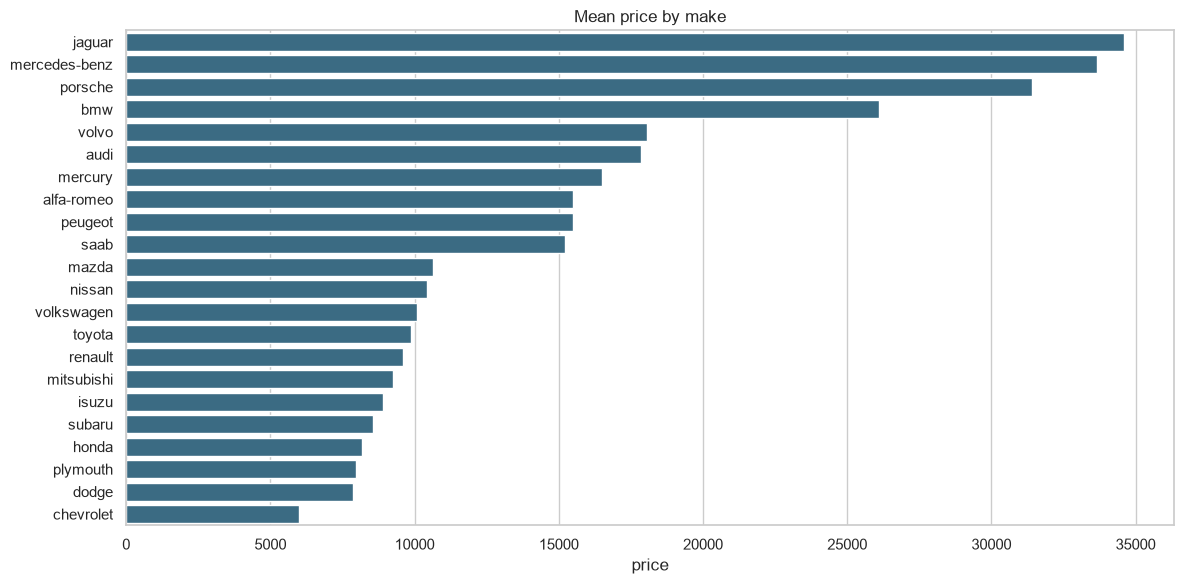

In [31]:
order = data.groupby("make")["price"].mean().sort_values(ascending=False).index
plt.figure(figsize=(12, 6))
sns.barplot(data=data, y="make", x="price", order=order, color=BLUE, errorbar=None)
plt.title("Mean price by make"); plt.ylabel("")
plt.tight_layout()

**What this shows.** Prices fall in three tiers: a luxury tier above 25,000 (Jaguar, Mercedes-Benz, Porsche, BMW), a middle tier of 12,000 to 20,000 (Volvo, Audi, Peugeot, Saab, Alfa Romeo) and a budget tier below 12,000 (Toyota, Nissan, Honda, Dodge and others).

## 4. Effect of the independent variables on price

### 4a. Continuous variables vs price

In [32]:
rows = []
for c in continuous:
    r, p = stats.pearsonr(data[c], data["price"])
    rho, _ = stats.spearmanr(data[c], data["price"])
    rows.append((c, r, p, rho))
corr_tbl = pd.DataFrame(rows, columns=["variable", "pearson_r", "p_value", "spearman_rho"]).set_index("variable")
corr_tbl["r_squared"] = corr_tbl["pearson_r"] ** 2
corr_tbl = corr_tbl.reindex(corr_tbl["pearson_r"].abs().sort_values(ascending=False).index)
corr_tbl.round(4)

,pearson_r,p_value,spearman_rho,r_squared
variable,,,,
engine-size,0.8723,0.0000,0.8284,0.7610
curb-weight,0.8344,0.0000,0.9138,0.6962
horsepower,0.8096,0.0000,0.8491,0.6554
city-L/100km,0.7899,0.0000,0.8313,0.6239
width,0.7513,0.0000,0.8121,0.5644
highway-mpg,-0.7047,0.0000,-0.8273,0.4966
length,0.6906,0.0000,0.8103,0.4770
city-mpg,-0.6866,0.0000,-0.8313,0.4714
wheel-base,0.5846,0.0000,0.6818,0.3418


**What this shows.** Ten continuous variables are significantly related to price (p < 0.001). The strongest are **`engine-size` (r = 0.87)**, **`curb-weight` (0.83)**, **`horsepower` (0.81)**, **`city-L/100km` (0.79)** and **`width` (0.75)**. Engine size alone explains 76% of the variation in price. Fuel economy is strongly negative (`highway-mpg` -0.70, `city-mpg` -0.69): bigger, thirstier cars cost more. `height`, `normalized-losses`, `peak-rpm`, `stroke` and `compression-ratio` show no meaningful relationship (r between -0.10 and 0.14, p above 0.05). Spearman rank correlations agree and are even higher for `curb-weight` (0.91), so the results are not driven by the extreme premium cars.

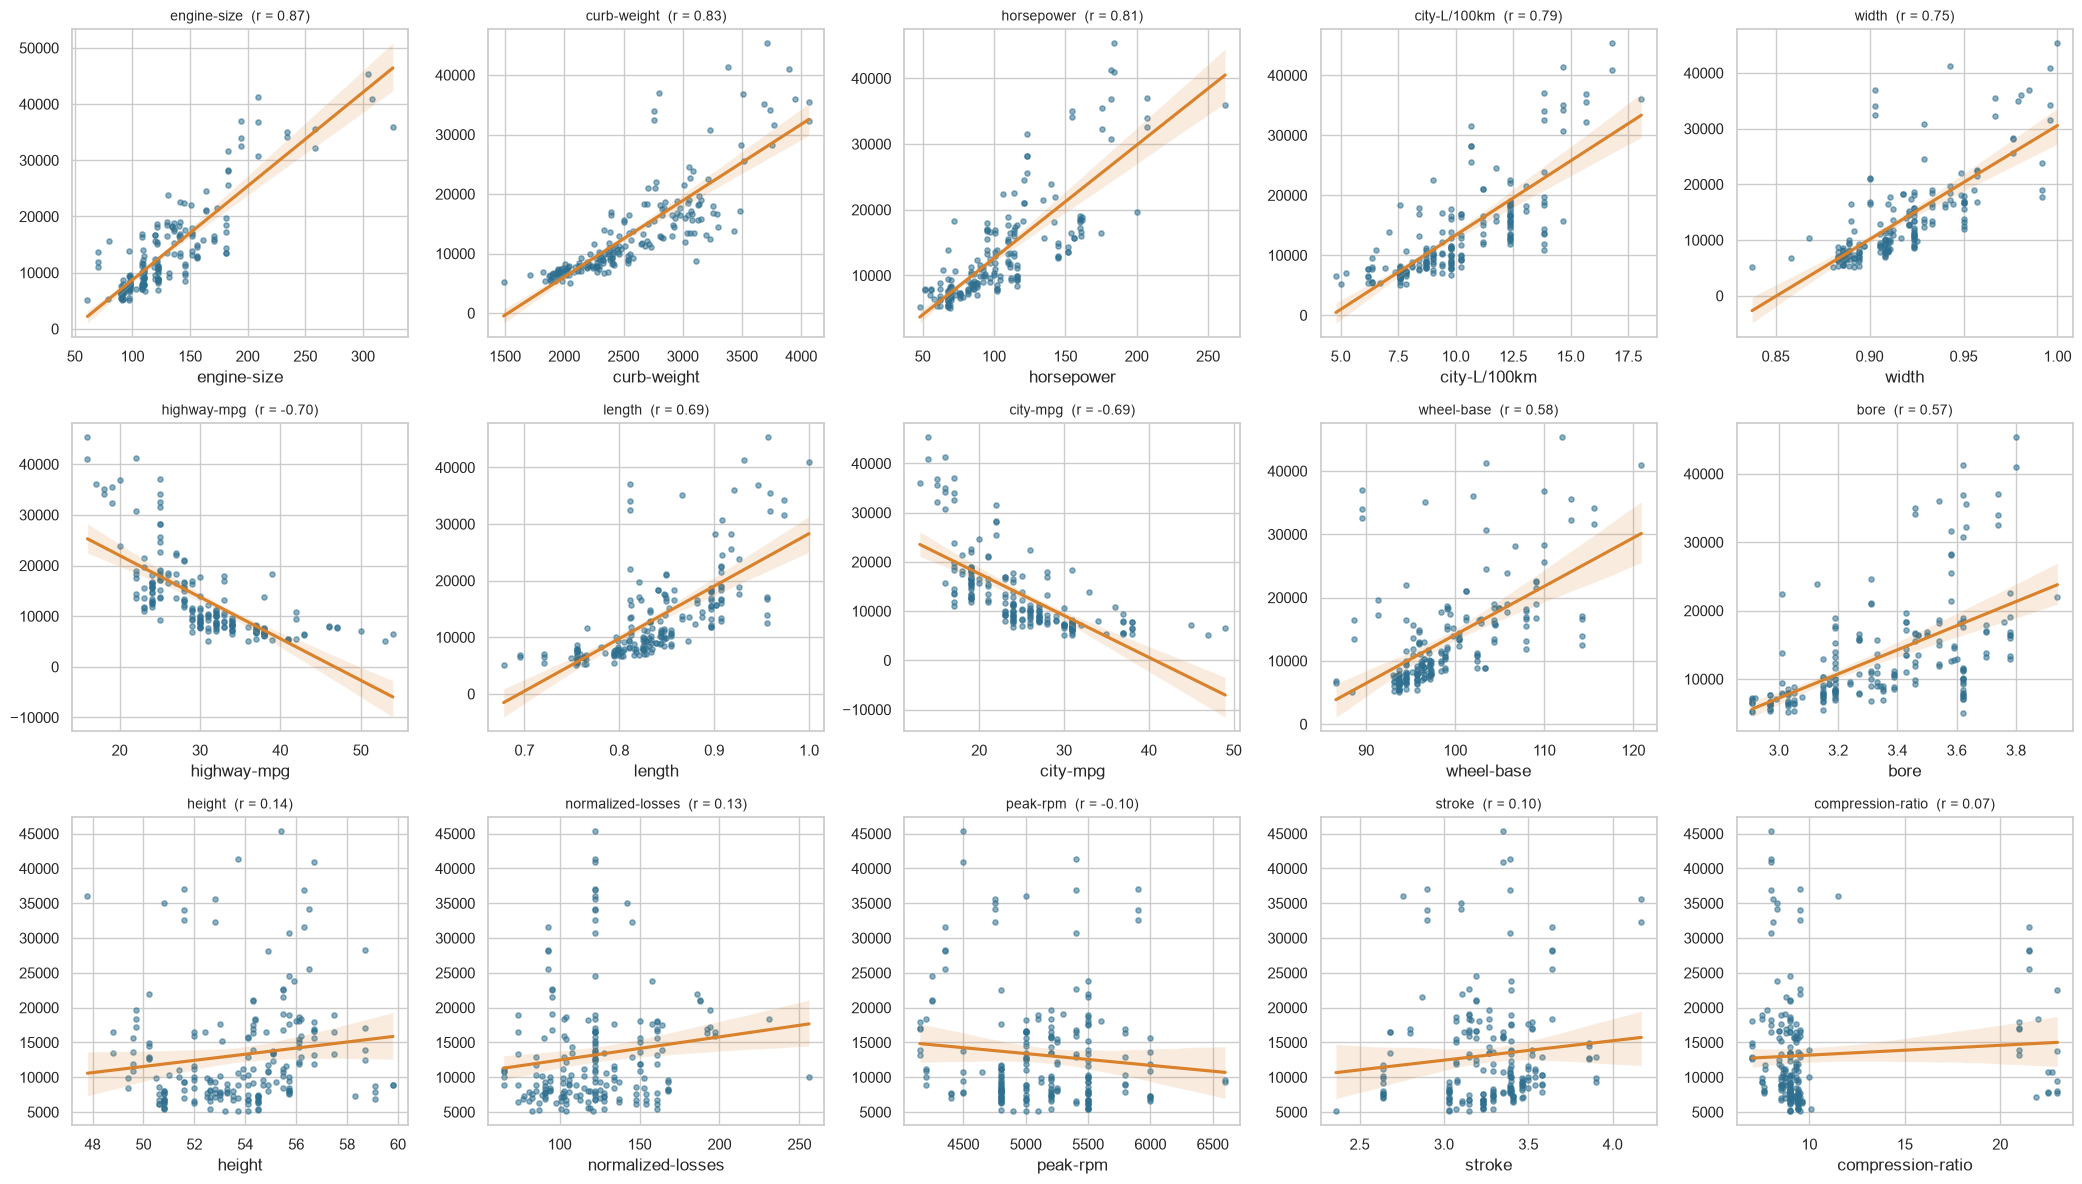

In [33]:
order = corr_tbl.index.tolist()
fig, axes = plt.subplots(3, 5, figsize=(21, 12))
for ax, c in zip(axes.ravel(), order):
    sns.regplot(data=data, x=c, y="price", scatter_kws=dict(s=14, alpha=.55, color=BLUE), line_kws=dict(color=ORANGE), ax=ax)
    ax.set_title(f"{c}  (r = {corr_tbl.loc[c, 'pearson_r']:.2f})", fontsize=10); ax.set_ylabel("")
plt.tight_layout()

**What this shows.** The panels are ordered by strength of correlation. The first row (engine size, curb weight, horsepower, city L/100km, width) shows a clear upward trend that the orange fitted line follows well, although the spread around it widens for larger, more expensive cars. The `highway-mpg` and `city-mpg` panels slope downward but are curved, not straight: price drops quickly between 15 and 30 mpg and then flattens, so the straight line (which even goes below zero) is only a rough guide for them. The bottom row (`height`, `normalized-losses`, `peak-rpm`, `stroke`, `compression-ratio`) shows a flat cloud with no pattern, confirming they are not useful on their own.

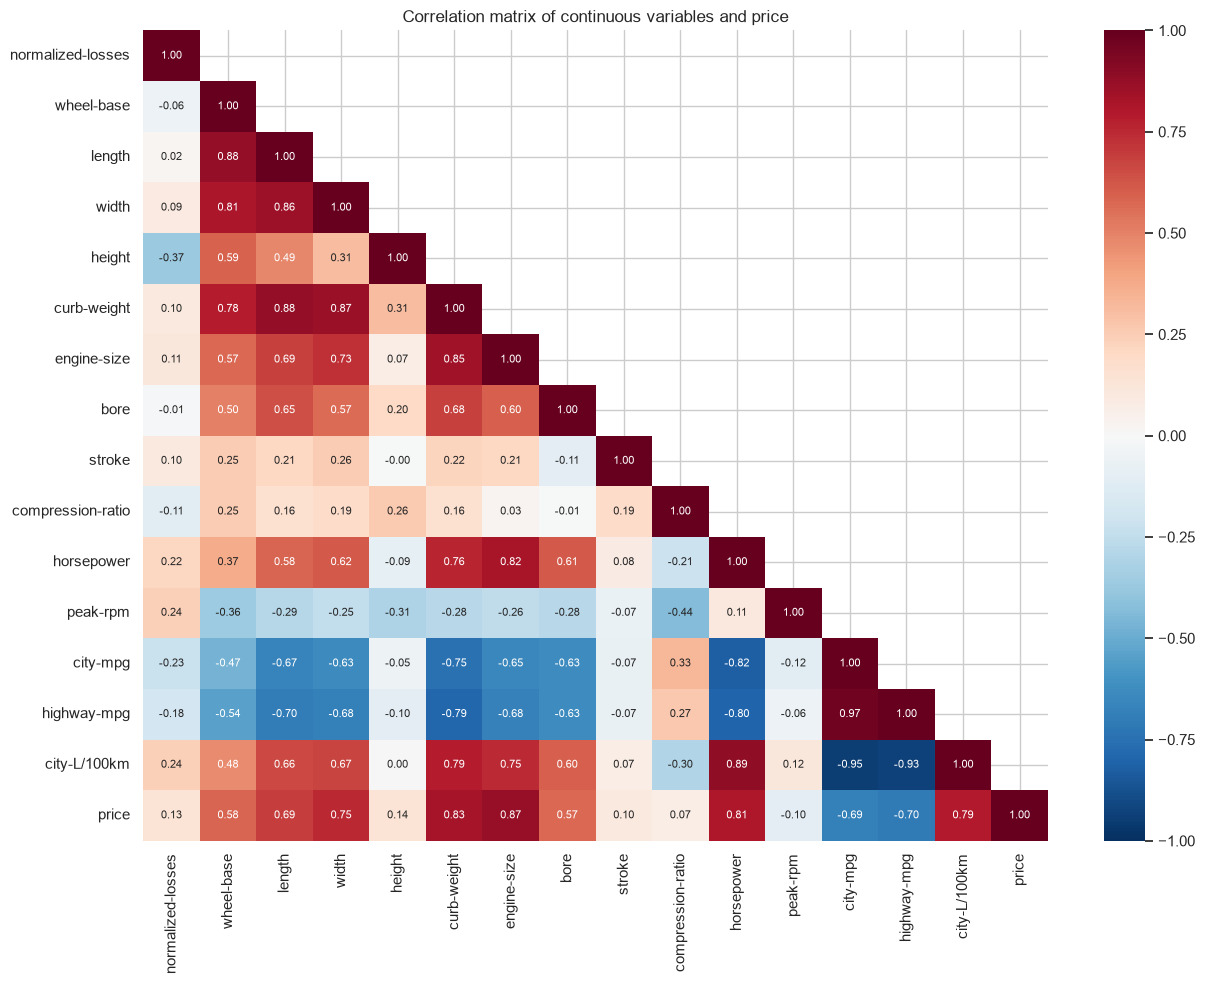

In [34]:
cm = data[continuous + ["price"]].corr()
mask = np.triu(np.ones_like(cm, dtype=bool), k=1)
plt.figure(figsize=(13, 10))
sns.heatmap(cm, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix of continuous variables and price")
plt.tight_layout()

**What this shows.** The size and power variables (`curb-weight`, `engine-size`, `horsepower`, `width`, `length`, `wheel-base`) are highly correlated with each other (0.6 to 0.9), and strongly negatively correlated with `city-mpg` and `highway-mpg`. This is **multicollinearity**: these variables mostly measure the same thing (how big and powerful the car is), so they overlap when predicting price. This matters for feature selection in Section 5.

### 4b. Categorical variables vs price

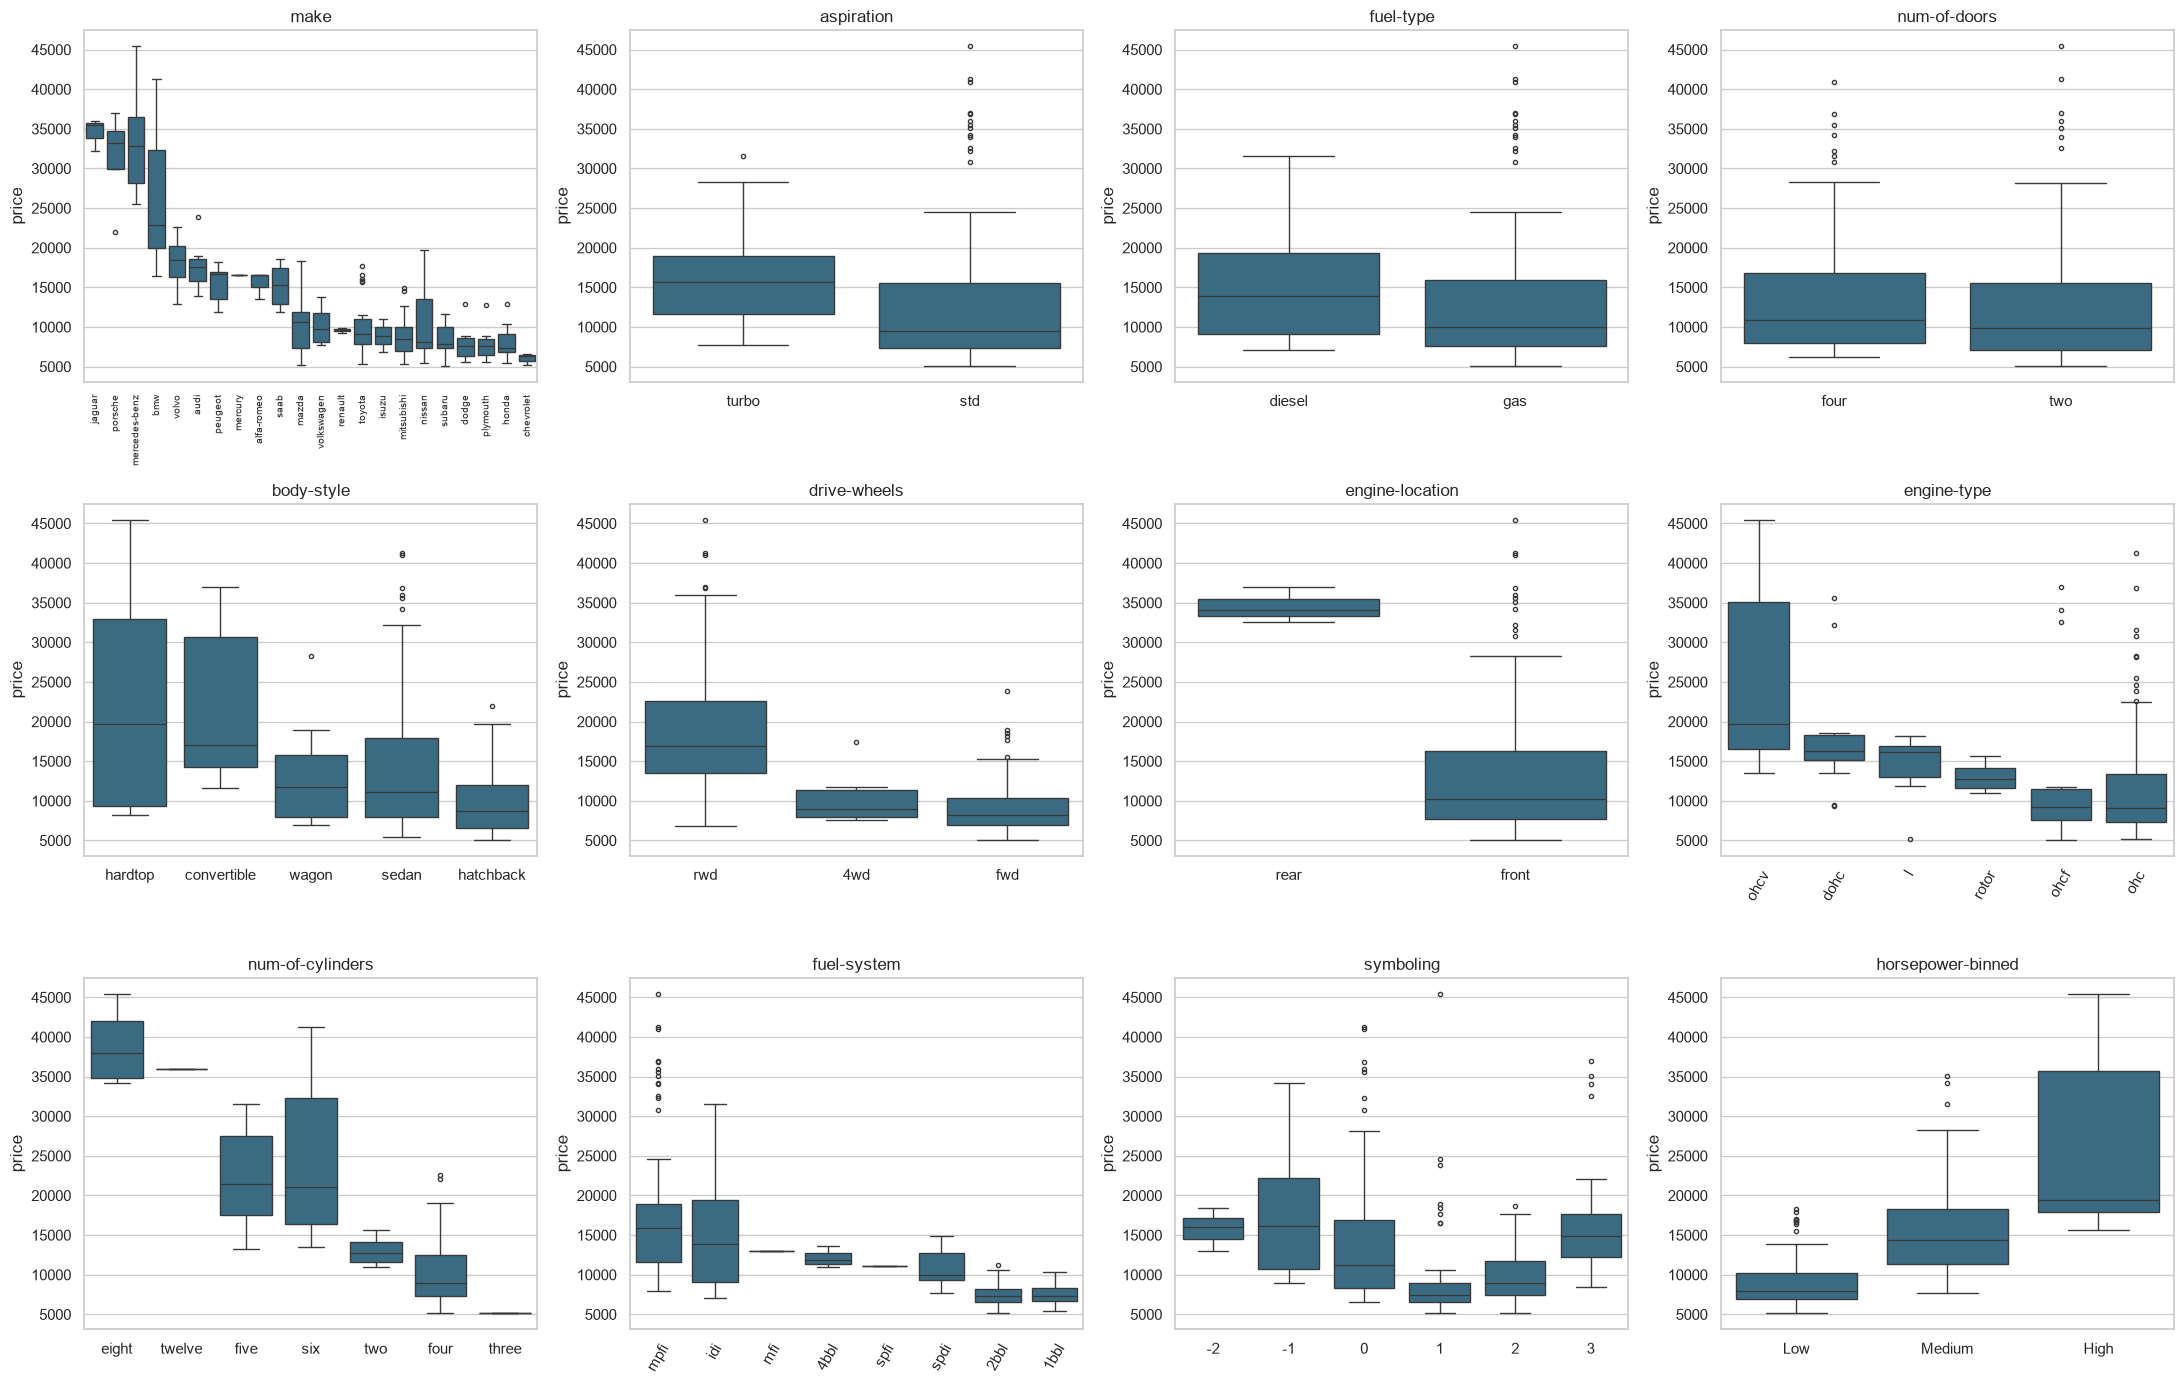

In [35]:
cats = [c for c in categorical if c not in ("symboling", "horsepower-binned")] + ["symboling", "horsepower-binned"]
fig, axes = plt.subplots(3, 4, figsize=(22, 14))
for ax, c in zip(axes.ravel(), cats):
    order = data.groupby(c)["price"].median().sort_values(ascending=False).index
    if c == "horsepower-binned": order = ["Low", "Medium", "High"]
    if c == "symboling": order = sorted(data[c].unique())
    sns.boxplot(data=data, x=c, y="price", order=order, color=BLUE, ax=ax, fliersize=3)
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=90 if c == "make" else (60 if c in ("fuel-system", "engine-type") else 0))
    if c == "make": ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()

**What this shows.** Box plots of price for every categorical variable.
- **Large differences:** `make` (luxury brands far above the rest), `num-of-cylinders` (eight-cylinder cars average about 3.8 times and six-cylinder cars about 2.3 times the price of a four-cylinder car), `horsepower-binned` (High cars have a median near 19,000 versus about 8,000 for Low), `drive-wheels` (rwd much higher), and `engine-location` (rear-engine Porsches are all above 32,000).
- **Moderate differences:** `engine-type` (ohcv highest), `fuel-system` (mpfi and idi above 2bbl and 1bbl), `body-style`, and `symboling` (a U-shaped pattern: the safest and the riskiest cars cost more than the middle).
- **Little difference:** `num-of-doors`, `fuel-type` and, to a lesser extent, `aspiration` have heavily overlapping boxes.

In [36]:
rows = []
for c in categorical:
    groups_ = [g["price"].values for _, g in data.groupby(c)]
    F, p = stats.f_oneway(*groups_)
    H, p_kw = stats.kruskal(*groups_)
    grand = data["price"].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups_)
    ss_total = ((data["price"] - grand) ** 2).sum()
    rows.append((c, data[c].nunique(), F, p, p_kw, ss_between / ss_total))
anova_tbl = pd.DataFrame(rows, columns=["variable", "n_groups", "F", "p_anova", "p_kruskal", "eta_squared"]).set_index("variable")
anova_tbl = anova_tbl.sort_values("eta_squared", ascending=False)
anova_tbl.round(4)

,n_groups,F,p_anova,p_kruskal,eta_squared
variable,,,,,
make,22,33.2321,0.0000,0.0000,0.7959
num-of-cylinders,7,54.9437,0.0000,0.0000,0.6295
horsepower-binned,3,108.5048,0.0000,0.0000,0.5229
drive-wheels,3,67.9541,0.0000,0.0000,0.4070
fuel-system,8,15.0244,0.0000,0.0000,0.3527
engine-type,6,9.8451,0.0000,0.0000,0.2016
body-style,5,9.1288,0.0000,0.0000,0.1570
symboling,6,6.8480,0.0000,0.0000,0.1494
engine-location,2,24.4956,0.0000,0.0054,0.1096


**What this shows.** One-way ANOVA (and the rank-based Kruskal-Wallis test as a check) for every categorical variable. η² is the share of price variance explained by the variable alone.
- **`make` is the strongest (η² = 0.80)**, then `num-of-cylinders` (0.63), `horsepower-binned` (0.52), `drive-wheels` (0.41) and `fuel-system` (0.35). All are significant (p < 0.001).
- `engine-type`, `body-style`, `symboling` and `engine-location` are significant but weaker (0.11 to 0.20).
- `aspiration` is weak (0.03; significant but small) and `fuel-type` (p = 0.12 ANOVA) and `num-of-doors` (p = 0.55) have **no reliable effect** on price.

Large η² for `make` partly reflects that brands sell different sizes of car, so it is not independent from the size variables. Several groups are tiny, so the F-tests for variables with many levels (like `make`) should be read as a guide, not as a precise figure.

### 4c. Two categorical variables

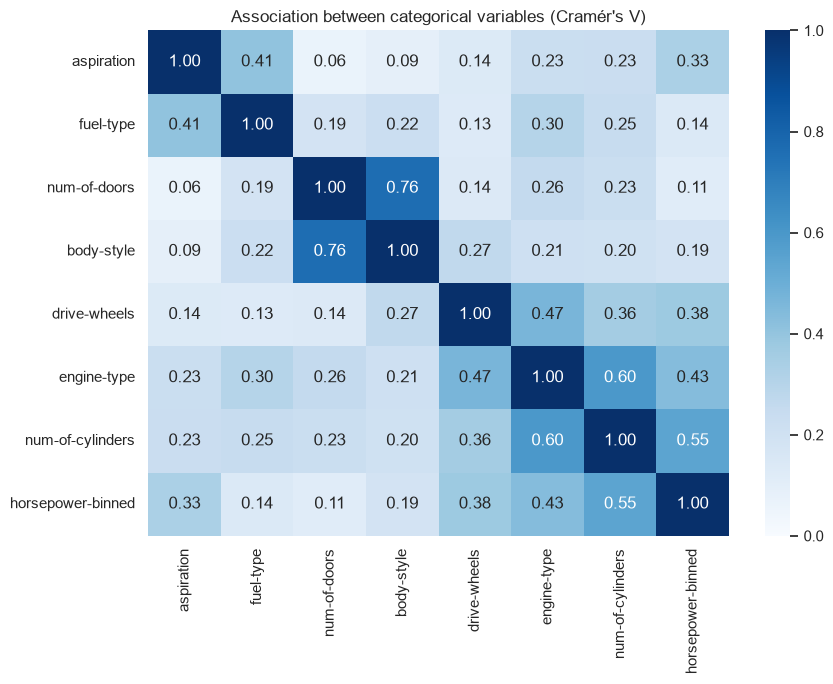

In [37]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); k = min(ct.shape) - 1
    return np.sqrt(chi2 / (n * k))

cc = ["aspiration", "fuel-type", "num-of-doors", "body-style", "drive-wheels", "engine-type", "num-of-cylinders", "horsepower-binned"]
V = pd.DataFrame([[cramers_v(data[a], data[b]) for b in cc] for a in cc], index=cc, columns=cc)
plt.figure(figsize=(9, 7))
sns.heatmap(V, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Association between categorical variables (Cramér's V)")
plt.tight_layout()

**What this shows.** Cramér's V measures association between two categorical variables (0 = none, 1 = perfect). The strongest pairs are `body-style` and `num-of-doors` (0.76, e.g. hatchbacks are mostly two-door and sedans four-door), `engine-type` and `num-of-cylinders` (0.60), and `num-of-cylinders` and `horsepower-binned` (0.55). So categorical variables also overlap, and `num-of-doors` adds almost nothing beyond `body-style`. `aspiration` and `fuel-type` are moderately linked (0.41) because most diesels are turbocharged.

drive-wheels  4wd  fwd  rwd
body-style                 
convertible     0    1    5
hardtop         0    1    7
hatchback       1   49   18
sedan           3   55   36
wagon           4   12    9

Chi-square = 29.1, dof = 8, p = 0.0003035, Cramer's V = 0.27



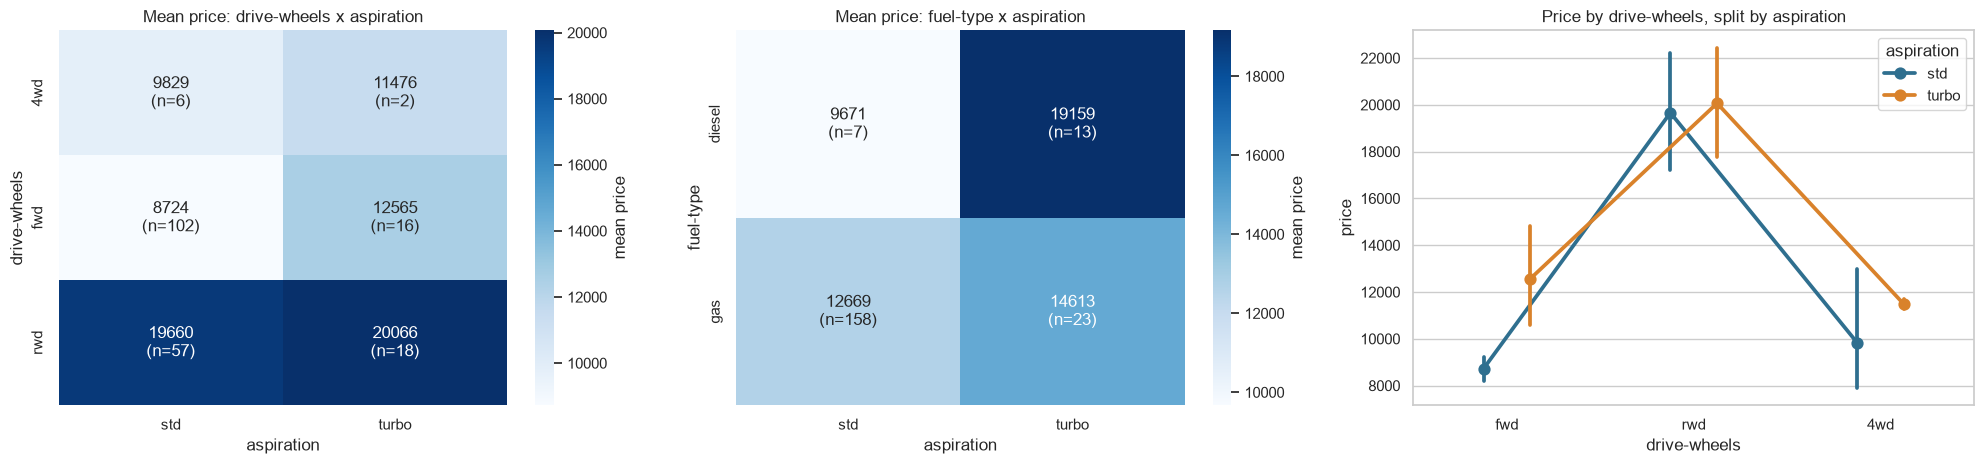

In [38]:
# (i) Are body-style and drive-wheels related to each other?
ct = pd.crosstab(data["body-style"], data["drive-wheels"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(ct.to_string())
print(f"\nChi-square = {chi2:.1f}, dof = {dof}, p = {p:.4g}, Cramer's V = {cramers_v(data['body-style'], data['drive-wheels']):.2f}\n")

# (ii) Does the effect of one variable on price depend on the other? Mean price for two pairs
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, (a, b) in zip(axes[:2], [("drive-wheels", "aspiration"), ("fuel-type", "aspiration")]):
    pm = data.pivot_table(values="price", index=a, columns=b, aggfunc="mean")
    pn = data.pivot_table(values="price", index=a, columns=b, aggfunc="count")
    sns.heatmap(pm, annot=pm.round(0).astype(int).astype(str) + "\n(n=" + pn.fillna(0).astype(int).astype(str) + ")", fmt="",
                cmap="Blues", ax=ax, cbar_kws={"label": "mean price"})
    ax.set_title(f"Mean price: {a} x {b}")
sns.pointplot(data=data, x="drive-wheels", y="price", hue="aspiration", order=["fwd", "rwd", "4wd"], dodge=.25, palette=[BLUE, ORANGE], ax=axes[2])
axes[2].set_title("Price by drive-wheels, split by aspiration")
plt.tight_layout()

**What this shows.** *Left table and test:* body style and drive-wheels are statistically related (chi-square = 29.1, p = 0.0003, V = 0.27): convertibles and hardtops are almost all rwd, hatchbacks and sedans are mostly fwd, and wagons are the main 4wd body style. This shows that the drive-wheels effect on price is partly a body-style effect. *Heatmaps and chart:* rwd cars are expensive regardless of aspiration (about 19,700 standard versus 20,100 turbo). For fwd cars a turbo adds about 3,800. Diesels are cheap when naturally aspirated (9,671) but expensive when turbocharged (19,159), while gas cars show a small turbo premium (12,669 versus 14,613). Some cells have only 2 to 13 cars, so those figures are indicative only.

In [39]:
# Statistical test of the interaction: is the turbo premium the same in fwd and rwd cars?
sub = data[data["drive-wheels"].isin(["fwd", "rwd"])]
for dw, g in sub.groupby("drive-wheels"):
    std_, turbo = g.loc[g.aspiration == "std", "price"], g.loc[g.aspiration == "turbo", "price"]
    t, p = stats.ttest_ind(turbo, std_, equal_var=False)
    print(f"{dw}: std n={len(std_)} mean {std_.mean():,.0f} | turbo n={len(turbo)} mean {turbo.mean():,.0f} | premium {turbo.mean()-std_.mean():+,.0f} (Welch p = {p:.3f})")

fwd: std n=102 mean 8,724 | turbo n=16 mean 12,565 | premium +3,841 (Welch p = 0.005)
rwd: std n=57 mean 19,660 | turbo n=18 mean 20,066 | premium +406 (Welch p = 0.826)


**What this shows.** The turbo premium depends on the drivetrain, which is an **interaction** between the two categorical variables. In front-wheel-drive cars turbo adds +3,841 (p = 0.005, significant), whereas in rear-wheel-drive cars it adds only +406 (p = 0.83, not significant). So a dealer cannot assume that "turbo means a higher price" in every segment.

## 5. Feature selection and recommendation

Three different feature-selection methods are used, then combined, so that the conclusion does not depend on one technique:

1. **Filter (statistical):** share of price variance explained by one variable alone: r² for continuous variables, η² (from ANOVA) for categorical ones. Both are on a 0 to 1 scale, so they can be ranked together.
2. **Mutual information:** captures any relationship (also non-linear) between a feature and price.
3. **Random-forest permutation importance:** how much prediction accuracy on unseen cars drops when a feature is shuffled. It accounts for the other features and handles non-linear effects.

`city-L/100km` is dropped from the candidate list because it is an exact transformation of `city-mpg`, and the binary `diesel`/`gas` columns are represented once as `fuel-type`.

In [40]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

num_f = [c for c in continuous if c != "city-L/100km"]
cat_f = [c for c in categorical if c not in ("horsepower-binned",)]          # 'horsepower-binned' is just a re-coding of horsepower
X, y = data[num_f + cat_f].copy(), data["price"]
X["symboling"] = X["symboling"].astype(str)
print(f"{len(num_f)} continuous + {len(cat_f)} categorical = {X.shape[1]} candidate features, {len(X)} cars")

14 continuous + 11 categorical = 25 candidate features, 201 cars


**What this shows.** The feature-selection set has 25 candidates (14 continuous, 11 categorical) for 201 cars. `city-L/100km` and `horsepower-binned` are left out as they are re-expressions of `city-mpg` and `horsepower`.

In [41]:
# Method 1: filter scores
filt = pd.concat([corr_tbl.loc[[c for c in num_f], "r_squared"],
                  anova_tbl.loc[[c for c in cat_f], "eta_squared"]]).rename("filter_score")
filt = filt.sort_values(ascending=False)
filt.round(3).to_frame()

,filter_score
variable,
make,0.796
engine-size,0.761
curb-weight,0.696
horsepower,0.655
num-of-cylinders,0.630
width,0.564
highway-mpg,0.497
length,0.477
city-mpg,0.471


**What this shows.** On its own, `make` explains the most price variance (0.80), followed by `engine-size` (0.76), `curb-weight` (0.70), `horsepower` (0.66) and `num-of-cylinders` (0.63). `fuel-type`, `num-of-doors`, `compression-ratio`, `stroke` and `peak-rpm` explain 1% or less.

In [42]:
# Method 2: mutual information (categoricals are label-coded and flagged as discrete)
Xmi = X.copy()
for c in cat_f: Xmi[c] = Xmi[c].astype("category").cat.codes
mi = mutual_info_regression(Xmi, y, discrete_features=[c in cat_f for c in Xmi.columns], random_state=RANDOM_STATE, n_neighbors=5)
mi = pd.Series(mi, index=Xmi.columns, name="mutual_info").sort_values(ascending=False)
mi.round(3).to_frame()

,mutual_info
curb-weight,0.928
highway-mpg,0.814
horsepower,0.802
engine-size,0.775
city-mpg,0.716
width,0.645
length,0.581
make,0.525
wheel-base,0.466
fuel-system,0.460


**What this shows.** Mutual information ranks the numeric size and power variables on top: `curb-weight` (0.93), `highway-mpg` (0.81), `horsepower` (0.80), `engine-size` (0.78) and `city-mpg` (0.72), with `width` and `length` next. Categorical variables with many levels, such as `make`, rank lower here (0.53). `fuel-type`, `num-of-doors` and `engine-location` carry almost no information.

In [43]:
# Method 3: random forest + permutation importance on held-out cars
pre = ColumnTransformer([("num", "passthrough", num_f), ("cat", OneHotEncoder(handle_unknown="ignore"), cat_f)])
rf = Pipeline([("pre", pre), ("rf", RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1))])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
rf.fit(X_tr, y_tr)
print(f"Random forest on unseen cars: R2 = {rf.score(X_te, y_te):.3f}")
pi = permutation_importance(rf, X_te, y_te, n_repeats=50, random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=X.columns, name="permutation_importance").sort_values(ascending=False)
perm.round(3).to_frame()

Random forest on unseen cars: R2 = 0.925


,permutation_importance
engine-size,0.368
curb-weight,0.288
width,0.022
horsepower,0.020
highway-mpg,0.017
city-mpg,0.010
normalized-losses,0.004
wheel-base,0.003
length,0.003
make,0.002


**What this shows.** A random forest trained on 75% of the cars predicts the other 25% with R² = 0.925, so the features do explain price well. Shuffling `engine-size` costs 0.37 of R² and `curb-weight` 0.29, far more than any other feature. Other features look unimportant (0.02 or less) because **they are correlated with these two**: once engine size and weight are known, `horsepower`, `width` or `length` add little. This method therefore tells us which feature to keep from each correlated group, and it should not be read as saying the others are irrelevant.

                   filter  mutual_info  perm_importance  mean_rank
curb-weight           3.0          1.0              2.0        2.0
engine-size           2.0          4.0              1.0        2.3
horsepower            4.0          3.0              4.0        3.7
highway-mpg           7.0          2.0              5.0        4.7
width                 6.0          6.0              3.0        5.0
make                  1.0          8.0             10.0        6.3
city-mpg              9.0          5.0              6.0        6.7
length                8.0          7.0              9.0        8.0
wheel-base           12.0          9.0              8.0        9.7
fuel-system          11.0         10.0             12.0       11.0
drive-wheels         10.0         13.0             14.0       12.3
num-of-cylinders      5.0         12.0             22.0       13.0
bore                 13.0         11.0             20.0       14.7
normalized-losses    20.0         18.0              7.0       

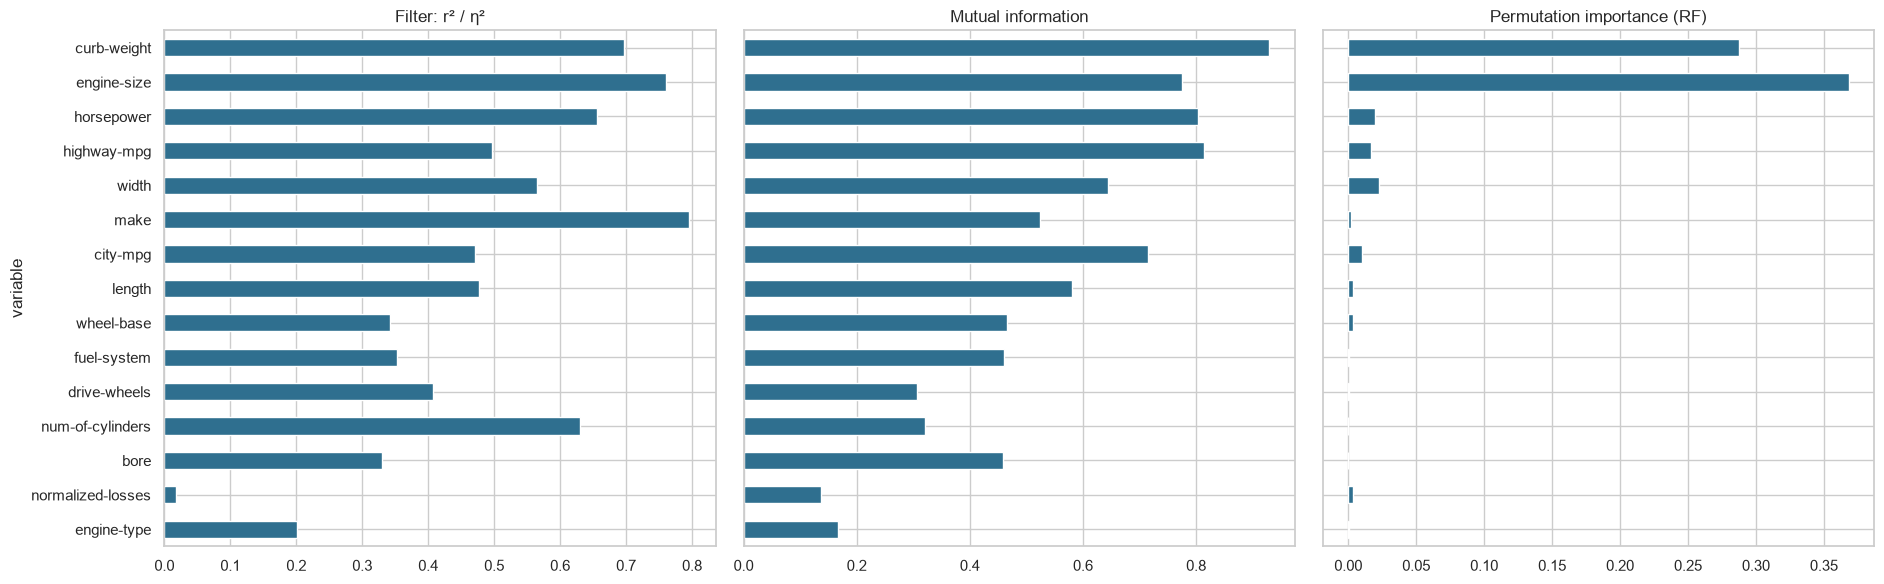

In [44]:
# Combine: rank each feature under each method (1 = most important) and average the ranks
ranks = pd.DataFrame({"filter": filt.rank(ascending=False), "mutual_info": mi.rank(ascending=False),
                      "perm_importance": perm.rank(ascending=False)})
ranks["mean_rank"] = ranks.mean(axis=1)
ranks = ranks.sort_values("mean_rank")
print(ranks.round(1).to_string())

top = ranks.head(10)
fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharey=True)
for ax, (name, s, col) in zip(axes, [("Filter: r² / η²", filt, BLUE), ("Mutual information", mi, BLUE), ("Permutation importance (RF)", perm, BLUE)]):
    s.loc[ranks.index[::-1][-15:][::-1]].plot.barh(ax=ax, color=col)
    ax.set_title(name); ax.invert_yaxis()
plt.tight_layout()

**What this shows.** Averaging the ranking from the three methods gives a consistent top group. The top 9, in order, are **`curb-weight` (mean rank 2.0), `engine-size` (2.3), `horsepower` (3.7), `highway-mpg` (4.7), `width` (5.0), `make` (6.3), `city-mpg` (6.7), `length` (8.0) and `wheel-base` (9.7)**. The bottom of the ranking (`fuel-type`, `num-of-doors`, `peak-rpm`, `compression-ratio`, `stroke`, `symboling`, `height`) is also consistent: each of these ranks 13th or lower under every method, which makes them safe to ignore. `drive-wheels` (rank 12.3) and `num-of-cylinders` (13.0) are useful but mostly through their link to size and power.

### 5.1 Do the top features really predict price? (cross-validated check)

      last feature added  RF cv R2  Linear cv R2
top_k                                           
1            curb-weight     0.580         0.638
2            engine-size     0.816         0.732
3             horsepower     0.858         0.741
4            highway-mpg     0.876         0.736
5                  width     0.883         0.753
6                   make     0.891         0.858
8                 length     0.888         0.856
10           fuel-system     0.888         0.850
15           engine-type     0.881         0.803
25             fuel-type     0.878         0.744


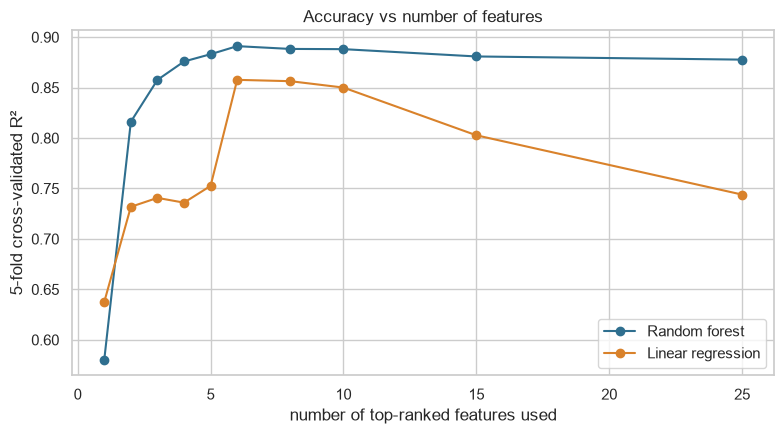

In [45]:
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
def cv_r2(features, model="rf"):
    nf = [f for f in features if f in num_f]; cf = [f for f in features if f in cat_f]
    pre_ = ColumnTransformer([("num", "passthrough", nf), ("cat", OneHotEncoder(handle_unknown="ignore"), cf)])
    est = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1) if model == "rf" else LinearRegression()
    return cross_val_score(Pipeline([("pre", pre_), ("m", est)]), X[features], y, cv=cv, scoring="r2").mean()

res = []
for k in [1, 2, 3, 4, 5, 6, 8, 10, 15, X.shape[1]]:
    feats = ranks.index[:k].tolist()
    res.append((k, feats[-1], cv_r2(feats, "rf"), cv_r2(feats, "lin")))
res = pd.DataFrame(res, columns=["top_k", "last feature added", "RF cv R2", "Linear cv R2"]).set_index("top_k")
print(res.round(3).to_string())

plt.figure(figsize=(8, 4.5))
plt.plot(res.index, res["RF cv R2"], marker="o", color=BLUE, label="Random forest")
plt.plot(res.index, res["Linear cv R2"], marker="o", color=ORANGE, label="Linear regression")
plt.xlabel("number of top-ranked features used"); plt.ylabel("5-fold cross-validated R²"); plt.legend(); plt.title("Accuracy vs number of features")
plt.tight_layout()

**What this shows.** Accuracy was measured on held-out cars (5-fold cross-validation) as more of the top-ranked features are used. With `curb-weight` alone the forest reaches R² = 0.58 and the linear model 0.64; adding `engine-size` lifts the forest to 0.82; the top 5 reach 0.88 and the top 6 (which add `make`) 0.89. After that, accuracy **stops improving** and for the linear model it actually **falls** (0.86 with 8 features, 0.74 with all 25), because many weak or overlapping variables add noise. A model with about 5 to 6 features is as good as one with all 25, which supports the selected list.

In [46]:
# The top continuous features measure overlapping things (size/weight/power). Check how redundant they are (VIF).
cont_top = [f for f in ranks.index[:12] if f in num_f]
Z = (data[cont_top] - data[cont_top].mean()) / data[cont_top].std()
vif = {c: 1 / (1 - LinearRegression().fit(Z.drop(columns=c), Z[c]).score(Z.drop(columns=c), Z[c])) for c in cont_top}
print(pd.Series(vif, name="VIF").round(1).sort_values(ascending=False).to_frame().to_string())
print("\nCorrelation among the strongest predictors:")
data[["curb-weight", "engine-size", "horsepower", "width", "length", "wheel-base", "highway-mpg"]].corr().round(2)

              VIF
city-mpg     24.6
highway-mpg  24.3
curb-weight  12.3
length        8.8
horsepower    7.1
wheel-base    6.6
engine-size   5.8
width         5.3

Correlation among the strongest predictors:


,curb-weight,engine-size,horsepower,width,length,wheel-base,highway-mpg
curb-weight,1.00,0.85,0.76,0.87,0.88,0.78,-0.79
engine-size,0.85,1.00,0.82,0.73,0.69,0.57,-0.68
horsepower,0.76,0.82,1.00,0.62,0.58,0.37,-0.80
width,0.87,0.73,0.62,1.00,0.86,0.81,-0.68
length,0.88,0.69,0.58,0.86,1.00,0.88,-0.70
wheel-base,0.78,0.57,0.37,0.81,0.88,1.00,-0.54
highway-mpg,-0.79,-0.68,-0.80,-0.68,-0.70,-0.54,1.00


**What this shows.** The variance inflation factor (VIF) shows how redundant a feature is given the others (above 5 is a common warning sign, above 10 is serious). The mpg variables (about 24) and `curb-weight` (12) are highly redundant, and `length`, `horsepower`, `wheel-base`, `engine-size` and `width` are between 5 and 9. The correlation table confirms that `curb-weight`, `engine-size`, `width` and `length` all move together (0.69 to 0.88). This is why a pricing model should keep one or two variables from each cluster rather than all of them.

In [47]:
# Size of the effects in dollars, for the dealer
q = data.groupby(pd.qcut(data["engine-size"], 4))["price"].mean().round(0)
print("Mean price by engine-size quartile:\n", q.to_string(), "\n")
slope = np.polyfit(data["curb-weight"], data["price"], 1)[0]
print(f"Each extra 100 lb of curb weight goes with about {slope*100:,.0f} higher price (simple regression).")
mk = data.groupby("make")["price"].agg(["count", "mean"]); mk = mk[mk["count"] >= 3]
# premium of the make over what its engine size alone predicts
b = np.polyfit(data["engine-size"], data["price"], 1)
data["resid"] = data["price"] - np.polyval(b, data["engine-size"])
prem = data.groupby("make")["resid"].agg(["count", "mean"]); prem = prem[prem["count"] >= 3].sort_values("mean", ascending=False)
print("\nPrice gap vs. what engine size alone predicts (by make):")
print(pd.concat([prem.head(4), prem.tail(3)]).round(0).to_string())

Mean price by engine-size quartile:
 engine-size
(60.999, 98.0]     7563.0
(98.0, 120.0]     10330.0
(120.0, 141.0]    13997.0
(141.0, 326.0]    22210.0 

Each extra 100 lb of curb weight goes with about 1,282 higher price (simple regression).

Price gap vs. what engine size alone predicts (by make):
               count    mean
make                        
porsche            4  8787.0
bmw                8  6237.0
audi               6  4019.0
mercedes-benz      8  3817.0
mitsubishi        13 -2538.0
nissan            18 -2961.0
jaguar             3 -4269.0


**What this shows.** The effect in money terms: cars in the largest engine-size quartile (above 141 cu in) average 22,210, nearly three times the smallest quartile (7,563). Each extra 100 lb of weight goes with roughly 1,282 more in price. After allowing for engine size, Porsche (+8,787), BMW (+6,237), Audi (+4,019) and Mercedes-Benz (+3,817) charge a **brand premium**, while Mitsubishi (-2,538) and Nissan (-2,961) sell below what their engines predict. (Jaguar looks negative only because a straight line underestimates the very largest engines.)

## 5.2 Conclusion and recommendation for the car dealer

**The variables with the most impact on price** (ranked by agreement across the filter, mutual-information and random-forest methods):

| Rank | Variable | Evidence |
|---|---|---|
| 1 | `curb-weight` | r = 0.83, best mutual information, 2nd in permutation importance |
| 2 | `engine-size` | r = 0.87 (explains 76% of price variance), top permutation importance |
| 3 | `horsepower` | r = 0.81, top 4 in all three methods |
| 4 | `highway-mpg` / `city-mpg` | r = -0.70 / -0.69: the mirror image of size and power (thirstier cars cost more) |
| 5 | `width` (and `length`) | r = 0.75 / 0.69, but largely overlaps with curb weight |
| 6 | `make` | alone explains 80% of price variance (η² = 0.80), a clear luxury / mid / budget tiering |
| Secondary | `drive-wheels`, `num-of-cylinders` | rwd cars cost about 2.1 times fwd cars; strongly tied to size and power |
| Not useful | `num-of-doors`, `fuel-type`, `peak-rpm`, `compression-ratio`, `stroke`, `height`, `symboling`, `normalized-losses` | weak or no relationship under every method |

Five or six of these variables predict price as well as all 25 do (cross-validated R² of about 0.88 to 0.89), and the three size and power variables overlap heavily with each other, so one or two of them are enough in a pricing rule.

**Recommendation for a dealer setting prices**

1. **Start from size and power.** Use engine size and curb weight as the base of the price. In this data the largest-engine quartile averages about 22,200 versus 7,600 for the smallest, and each extra 100 lb goes with roughly 1,300 more. Horsepower and fuel economy add little once those two are known, so there is no need to price them separately.
2. **Then adjust for brand.** Make has a large effect that size alone does not explain: after allowing for engine size, Porsche, BMW, Audi and Mercedes-Benz carry a premium of about 4,000 to 8,800, while Mitsubishi and Nissan sell about 2,500 to 3,000 below the size-based expectation.
3. **Add drivetrain and body style as second-order adjustments.** Rear-wheel-drive cars, especially hardtops and convertibles, command the highest prices (rwd hardtop about 24,200); front-wheel-drive hatchbacks are the cheapest segment. Turbo is worth about +3,800 on front-wheel-drive cars but showed no reliable premium on rear-wheel-drive cars, so do not apply one flat turbo markup.
4. **Do not price on** number of doors, gas or diesel, compression ratio, stroke, peak rpm or height. These showed no consistent link to price.

**Limitations.** The data has only 201 cars from one period, and several groups are very small (3 rear-engine cars, 1 Mercury, 8 four-wheel-drive cars), so group averages for those should be treated as indications. The findings show association, not proof that changing one feature would change what buyers pay. The model should be checked against current market prices before use.